In [2]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings, ChatGoogleGenerativeAI
from langchain_core.tools import tool
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate

from dotenv import load_dotenv
import theme

import pandas as pd
import geopandas as gpd

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point, MultiPolygon

import time
import os
import sys
import contextlib
import io
import re
from IPython.display import Image, Markdown, display
import unicodedata
from typing import Optional

# API KEY
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")

if api_key:
  print("API key cargada correctamente")
else:
  raise RuntimeError("No se encontró GEMINI_API_KEY en el archivo .env "
                    "Verificá que el archivo .env exista en la raíz del proyecto "
                    "y contenga la variable GEMINI_API_KEY"
  )
# Enbeddings
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

os.makedirs("./generated_images", exist_ok=True)

c:\Users\Usuario\.pyenv\pyenv-win\versions\3.13.3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


API key cargada correctamente


## Cargar base vectorial local

In [3]:
# Cargar la base vectorial Chroma ya existente
vectorstore = Chroma(
    collection_name="smn_documentos",
    embedding_function=embeddings,
    persist_directory="./chroma_db_smn"
)

print(
    "Documentos cargados desde Chroma:",
    vectorstore._collection.count()
)

# Crear retriever
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)

Documentos cargados desde Chroma: 367


## Cargar PDFs y generar base vectorial Chroma

**NOTA:** *Se detectan documentos existentes ya cargados. Solo se tienen en cuenta documentos nuevos.*

In [147]:
# Lista de documentos existentes
registros_existentes = vectorstore._collection.get(include=["metadatas"])
fuentes_procesadas = set()

if registros_existentes and registros_existentes.get("metadatas"):
    for meta in registros_existentes["metadatas"]:
        if meta and "source" in meta:
            fuentes_procesadas.add(os.path.abspath(meta["source"]))

# Cargar PDFs
loader = PyPDFDirectoryLoader("files")
todos_los_documentos = loader.load()

# Documentos nuevos
documentos_nuevos = [
    doc for doc in todos_los_documentos 
    if os.path.abspath(doc.metadata.get("source", "")) not in fuentes_procesadas
]

print(f"Páginas detectadas nuevas: {len(documentos_nuevos)}")

if len(documentos_nuevos) == 0:
    print("No hay documentos nuevos para agregar.")
else:

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=500,
        chunk_overlap=50
    )
    docs_split_nuevos = text_splitter.split_documents(documentos_nuevos)
    print(f"Nuevos fragmentos generados: {len(docs_split_nuevos)}")

    # Tener en cuenta los limites de la API
    batch_size = 75
    total = len(docs_split_nuevos)

    for i in range(0, total, batch_size):
        lote = docs_split_nuevos[i:i + batch_size]

        print(f"Procesando lote {i // batch_size + 1}: documentos {i + 1} a {min(i + batch_size, total)}")

        # add_documents agrega sin borrar el contenido anterior
        vectorstore.add_documents(lote)

        print(f"Documentos guardados hasta ahora: {vectorstore._collection.count()}")

        if i + batch_size < total:
            print("Esperando 60 segundos para respetar la cuota...\n")
            time.sleep(60)

    print("\nNuevos documentos agregados correctamente.")
    print("Total actualizado de documentos almacenados:", vectorstore._collection.count())

Páginas detectadas nuevas: 100
Nuevos fragmentos generados: 296
Procesando lote 1: documentos 1 a 75
Documentos guardados hasta ahora: 551
Esperando 60 segundos para respetar la cuota...

Procesando lote 2: documentos 76 a 150
Documentos guardados hasta ahora: 626
Esperando 60 segundos para respetar la cuota...

Procesando lote 3: documentos 151 a 225
Documentos guardados hasta ahora: 701
Esperando 60 segundos para respetar la cuota...

Procesando lote 4: documentos 226 a 296
Documentos guardados hasta ahora: 772

Nuevos documentos agregados correctamente.
Total actualizado de documentos almacenados: 772


## Funciones de ayuda

In [4]:
def normalizar_texto(texto: str) -> str:
  """Elimina tildes, mayúsculas y espacios innecesarios para facilitar coincidencias."""
  if not texto:
    return ""
  texto = texto.strip().upper()
  texto = unicodedata.normalize('NFD', texto)
  texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
  return texto

def filtrar_poligono_tdf(geometry, modo: str = "continental"):
  """
  Separa los polígonos de la provincia de Tierra del Fuego, Antártida e Islas del Atlántico Sur.
  - 'continental': Conserva únicamente la Isla Grande e Isla de los Estados (lat > -55 y long < -55).
  - 'antartida': Conserva el Sector Antártico e islas australes (lat <= -55 o long >= -55).
  """
  if isinstance(geometry, MultiPolygon):
    if modo == "continental":
      polygons = [p for p in geometry.geoms if p.centroid.y > -55 and p.centroid.x < -55]
    elif modo == "antartida":
      polygons = [p for p in geometry.geoms if p.centroid.y <= -55 or p.centroid.x >= -55]
    else:
      return geometry
    return MultiPolygon(polygons) if polygons else geometry
  return geometry

def procesar_y_renderizar_respuesta(resultado: dict) -> str:
  """
  Extrae la respuesta del agente, renderiza el texto en formato Markdown 
  e intercala/muestra las imágenes generadas (vía marcadores o fallback).
  Devuelve el texto completo para ser guardado en el historial.
  """
  # 1. Obtener texto de respuesta
  output_data = resultado.get("output", "")

  if isinstance(output_data, list):
    output_text = "\n".join(
      b["text"]
      for b in output_data
      if isinstance(b, dict) and "text" in b
    )
  else:
    output_text = str(output_data)

  # 2. Buscar marcadores de imágenes
  patron = re.compile(
    r"\[\[IMAGEN_GENERADA:(.*?)\]\]"
    r"|^\s*IMAGEN_GENERADA:(\S+)\s*$",
    re.MULTILINE
  )

  matches = list(patron.finditer(output_text))

  # 3. Mostrar texto + imágenes intercalados
  posicion_actual = 0
  imagenes_mostradas = set()

  for match in matches:
    texto = output_text[posicion_actual:match.start()].strip()

    if texto:
      display(Markdown(texto))

    path_imagen = (
      match.group(1)
      if match.group(1) is not None
      else match.group(2)
    )
    path_imagen = path_imagen.strip()

    if path_imagen and os.path.exists(path_imagen):
      if path_imagen not in imagenes_mostradas:
        display(Image(filename=path_imagen))
        imagenes_mostradas.add(path_imagen)
    else:
      print(f"⚠️ No se encontró la imagen generada: {path_imagen}")

    posicion_actual = match.end()

  # 4. Mostrar el texto restante después de la última imagen
  texto_restante = output_text[posicion_actual:].strip()
  if texto_restante:
    display(Markdown(texto_restante))

  # 5. Fallback: Imágenes generadas por herramientas pero omitidas en el texto por el LLM
  imagenes_generadas = []
  for action, observation in resultado.get("intermediate_steps", []):
    if isinstance(observation, str):
      for linea in observation.splitlines():
        if linea.startswith("IMAGEN_GENERADA:"):
          path_imagen = linea.split("IMAGEN_GENERADA:", 1)[1].strip()
          if path_imagen and path_imagen not in imagenes_generadas:
            imagenes_generadas.append(path_imagen)

  for path_imagen in imagenes_generadas:
    if path_imagen not in imagenes_mostradas:
      if os.path.exists(path_imagen):
        display(Image(filename=path_imagen))
        imagenes_mostradas.add(path_imagen)
      else:
        print(f"⚠️ No se encontró la imagen generada: {path_imagen}")

  return output_text

## Carga de datasets

In [144]:
# ================================================================
# Temperaturas de los ultimos 365 dias
# ================================================================

print('='*50)
print("Temperaturas de los ultimos 365 dias")
print('='*50)

df_temps_365d = pd.read_csv(
    "datasets/temperaturas_365d.csv",
    parse_dates=["fecha"]
)

# Limpieza mínima de seguridad
df_temps_365d["estacion"] = df_temps_365d["estacion"].str.strip()

df_temps_365d = df_temps_365d.sort_values(
    by=["estacion", "fecha"]
).reset_index(drop=True)

# Verificaciones
print("\nCantidad de registros:", len(df_temps_365d))

print("\nRango de fechas:")
print("Desde:", df_temps_365d["fecha"].min())
print("Hasta:", df_temps_365d["fecha"].max())

print("\nValores faltantes:")
print(df_temps_365d.isna().sum())

display(df_temps_365d.head())

# ================================================================
# Validación de calidad de datos climáticos (outliers)
# ================================================================

print('='*50)
print("Validación de calidad de datos climáticos")
print('='*50)

# 1. Registros con tmax menor que tmin (inconsistencia física)
inconsistentes = df_temps_365d[df_temps_365d["tmax"] < df_temps_365d["tmin"]]
print(f"\nRegistros con tmax < tmin: {len(inconsistentes)}")
if not inconsistentes.empty:
    display(inconsistentes.head())

# 2. Valores fuera de un rango físicamente plausible para Argentina (-40°C a 50°C)
fuera_de_rango = df_temps_365d[
    (df_temps_365d["tmax"] < -40) | (df_temps_365d["tmax"] > 50) |
    (df_temps_365d["tmin"] < -40) | (df_temps_365d["tmin"] > 50)
]
print(f"Registros con temperaturas fuera de rango plausible: {len(fuera_de_rango)}")

# 3. Huecos en la serie temporal por estación (días faltantes)
huecos_por_estacion = {}
for estacion, grupo in df_temps_365d.groupby("estacion"):
    rango_completo = pd.date_range(grupo["fecha"].min(), grupo["fecha"].max(), freq="D")
    faltantes = rango_completo.difference(grupo["fecha"])
    if len(faltantes) > 0:
        huecos_por_estacion[estacion] = len(faltantes)

print(f"\nEstaciones con huecos en la serie temporal: {len(huecos_por_estacion)}")
if huecos_por_estacion:
    display(
        pd.Series(huecos_por_estacion, name="dias_faltantes")
        .sort_values(ascending=False)
        .head(10)
    )


# ================================================================
# Estadísticas normales climatológicas 1991-2020
# ================================================================

print('='*50)
print("Estadísticas normales climatológicas 1991-2020")
print('='*50)

df_temps_normales = pd.read_csv(
    "datasets/estadisticas_normales_1991-2020.csv"
)

# Limpiar espacios por seguridad
df_temps_normales["estacion"] = df_temps_normales["estacion"].str.strip()
df_temps_normales["valor"] = df_temps_normales["valor"].str.strip()

print("\nCantidad de registros:", len(df_temps_normales))
print("Cantidad de estaciones:", df_temps_normales["estacion"].nunique())

display(df_temps_normales.head())

# ================================================================
# Lista de estaciones meteorologicas
# ================================================================

print('='*50)
print("Lista de estaciones meteorologicas")
print('='*50)

df_lista_estaciones = pd.read_csv(
    "datasets/estaciones_meteorologicas.csv"
)

REEMPLAZOS_PROVINCIAS = {
    "SANTIAGO DEL ES": "SANTIAGO DEL ESTERO",
    "TIERRA DEL FUEG": "TIERRA DEL FUEGO",
}

df_lista_estaciones["provincia"] = df_lista_estaciones["provincia"].str.strip().replace(REEMPLAZOS_PROVINCIAS)
df_lista_estaciones["PROVINCIA_NORM"] = df_lista_estaciones["provincia"].astype(str).apply(normalizar_texto)

print("\nCantidad de registros:", len(df_lista_estaciones))

display(df_lista_estaciones.head())

# ================================================================
# Mapa base de provincias
# ================================================================

print('='*50)
print("Mapa base de provincias")
print('='*50)

path_geojson = "./data/provincias.geojson"

if os.path.exists(path_geojson):
    gdf_provincias = gpd.read_file(path_geojson)
    gdf_provincias["NOMBRE_NORM"] = gdf_provincias["nombre"].astype(str).apply(normalizar_texto)
    print("Cantidad de provincias/entidades:", len(gdf_provincias))
    display(gdf_provincias.head())
else:
    print(f"\n[ERROR] No se encontró el archivo del mapa provincial en {path_geojson}")
    gdf_provincias = None


Temperaturas de los ultimos 365 dias

Cantidad de registros: 42949

Rango de fechas:
Desde: 2025-09-28 00:00:00
Hasta: 2026-09-27 00:00:00

Valores faltantes:
fecha          0
tmax        2075
tmin         557
estacion       0
dtype: int64


,fecha,tmax,tmin,estacion
0,2025-09-28,23.6,10.8,AEROPARQUE AERO
1,2025-09-29,21.6,13.8,AEROPARQUE AERO
2,2025-09-30,24.5,15.5,AEROPARQUE AERO
3,2025-10-01,21.7,14.3,AEROPARQUE AERO
4,2025-10-02,21.2,16.3,AEROPARQUE AERO


Validación de calidad de datos climáticos

Registros con tmax < tmin: 0
Registros con temperaturas fuera de rango plausible: 2

Estaciones con huecos en la serie temporal: 6


CHILECITO AERO              72
VICTORICA                   24
OBERA                       12
BENITO JUAREZ AERO           9
SANTA CRUZ AERO              2
GOBERNADOR GREGORES AERO     1
Name: dias_faltantes, dtype: int64

Estadísticas normales climatológicas 1991-2020

Cantidad de registros: 784
Cantidad de estaciones: 98


,estacion,valor,enero,febrero,marzo,abril,mayo,junio,julio,agosto,septiembre,octubre,noviembre,diciembre
0,LA QUIACA OBSERVATORIO,Temperatura (°C),13.2,13.0,12.8,11.3,7.3,4.8,4.5,7.0,10.0,12.4,13.4,13.9
1,LA QUIACA OBSERVATORIO,Temperatura máxima (°C),20.6,20.4,20.6,20.3,17.8,16.3,16.1,18.0,20.0,21.7,22.5,22.2
2,LA QUIACA OBSERVATORIO,Temperatura mínima (°C),7.7,7.6,6.6,3.1,-2.5,-5.7,-6.2,-4.0,-0.4,3.3,5.5,7.3
3,LA QUIACA OBSERVATORIO,Humedad relativa (%),62.6,63.2,60.3,46.0,32.6,27.4,25.7,26.7,32.1,42.4,48.6,55.8
4,LA QUIACA OBSERVATORIO,Velocidad del Viento (km/h),6.5,6.8,6.7,5.5,4.8,5.5,5.9,6.7,7.9,7.9,7.7,7.1


Lista de estaciones meteorologicas

Cantidad de registros: 118


,nombre,provincia,latitud,longitud,altura,nro,nro_oaci,PROVINCIA_NORM
0,BASE BELGRANO II,ANTARTIDA,-77.866667,-34.616667,256,89034.0,SAYB,ANTARTIDA
1,BASE CARLINI (EX JUBANY),ANTARTIDA,-62.233333,-58.650000,11,89053.0,SAYJ,ANTARTIDA
2,BASE ESPERANZA,ANTARTIDA,-63.383333,-56.983333,24,88963.0,SAYE,ANTARTIDA
3,BASE MARAMBIO,ANTARTIDA,-64.233333,-56.616667,198,89055.0,SAWB,ANTARTIDA
4,BASE ORCADAS,ANTARTIDA,-60.733333,-44.733333,12,88968.0,SAYO,ANTARTIDA


Mapa base de provincias
Cantidad de provincias/entidades: 24


,id,nombre,nombre_completo,fuente,categoria,centroide,iso_id,iso_nombre,geometry,NOMBRE_NORM
0,02,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,IGN,Ciudad Autónoma,"{'lon': -58.445876325, 'lat': -34.614442065}",AR-C,Ciudad Autónoma de Buenos Aires,"POLYGON ((-58.45535 -34.52776, -58.45085 -34.5...",CIUDAD AUTONOMA DE BUENOS AIRES
1,58,Neuquén,Provincia del Neuquén,IGN,Provincia,"{'lon': -70.119897224, 'lat': -38.641982863}",AR-Q,Neuquén,"POLYGON ((-70.39341 -36.15624, -70.39499 -36.1...",NEUQUEN
2,74,San Luis,Provincia de San Luis,IGN,Provincia,"{'lon': -66.025231271, 'lat': -33.761103538}",AR-D,San Luis,"POLYGON ((-67.05547 -31.85605, -67.00593 -31.8...",SAN LUIS
3,82,Santa Fe,Provincia de Santa Fe,IGN,Provincia,"{'lon': -60.950687277, 'lat': -30.708822709}",AR-S,Santa Fe,"POLYGON ((-61.04639 -27.998, -58.884 -28, -58....",SANTA FE
4,46,La Rioja,Provincia de La Rioja,IGN,Provincia,"{'lon': -67.181757581, 'lat': -29.684937278}",AR-F,La Rioja,"POLYGON ((-68.52136 -27.81792, -68.51099 -27.8...",LA RIOJA


## Definicion de Tools

In [6]:
# Crear herramienta para buscar información en los PDF
@tool
def buscar_informacion_texto(query: str) -> str:
  """Útil para buscar explicaciones conceptuales, definiciones técnicas o informes climáticos en los documentos PDF."""
  results = retriever.invoke(query)
  
  if not results:
    return "No se encontró información relevante en los informes."

  # Formatear la respuesta incluyendo fuente y página
  respuesta = []
  for doc in results:
    fuente = doc.metadata.get("source", "PDF desconocido")
    pagina = doc.metadata.get("page", 0) + 1
    respuesta.append(f"--- [Fuente: {fuente} (Pág. {pagina})] ---\n{doc.page_content}")
  
  return "\n\n".join(respuesta)

In [121]:
# Herramienta para consultar los documentos disponibles en la base vectorial

@tool
def listar_documentos_disponibles() -> str:
  """
  Muestra el inventario de informes o documentos disponibles en el sistema RAG.
  Úsalo cuando el usuario pregunte qué información, informes o fechas hay en la base de datos.
  """
  if 'vectorstore' not in globals() or vectorstore is None:
    return "Error: La base de datos vectorial 'vectorstore' no está cargada."

  try:
    # Obtener únicamente los metadatos almacenados en la colección de Chroma
    datos = vectorstore.get(include=["metadatas"])
    metadatos = datos.get("metadatas", [])

    if not metadatos:
      return "No hay documentos cargados en la base de datos."

    # Extraer los títulos o nombres de archivo (ajusta la clave 'fuente' o 'source' o 'titulo' según tus metadatos)
    titulos = set()
    for meta in metadatos:
      if meta:
        # Intenta buscar 'titulo', 'source' o 'fuente' dentro del diccionario de metadatos
        nombre = meta.get("titulo") or meta.get("source") or meta.get("fuente")
        if nombre:
          titulos.add(str(nombre))

    if not titulos:
      return "Se encontraron registros en la base de datos, pero no contienen la clave 'titulo' o 'source' en sus metadatos."

    informes_ordenados = sorted(list(titulos))
    return f"Informes disponibles en el sistema:\n- " + "\n- ".join(informes_ordenados)

  except Exception as e:
    return f"Error al consultar los metadatos de la base vectorial: {str(e)}"

In [91]:
# Crear herramienta para graficar temperaturas de una estación
@tool
def graficar_temperatura_estacion(
  estacion: str,
  fecha_inicio: str,
  fecha_fin: str
) -> str:
  """
  Genera un gráfico de temperatura máxima y mínima para una estación
  meteorológica del SMN dentro de un rango de fechas. Incluye la banda 
  de amplitud térmica, extremos destacados e indicadores estadísticos.

  Args:
    estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
    fecha_inicio: Fecha inicial en formato YYYY-MM-DD.
    fecha_fin: Fecha final en formato YYYY-MM-DD.
  """

  # Convertir las fechas recibidas a datetime
  inicio = pd.to_datetime(fecha_inicio, errors="coerce")
  fin = pd.to_datetime(fecha_fin, errors="coerce")

  if pd.isna(inicio) or pd.isna(fin):
    return "Las fechas deben tener formato YYYY-MM-DD."

  if inicio > fin:
    return "La fecha de inicio no puede ser posterior a la fecha de fin."

  # Buscar la estación ignorando mayúsculas/minúsculas
  nombre_buscado = estacion.strip().upper()
  estaciones = df_temps_365d["estacion"].dropna().unique()

  coincidencias = [
    e for e in estaciones
    if nombre_buscado in e.upper()
  ]

  if len(coincidencias) == 0:
    return f"No se encontró ninguna estación que coincida con '{estacion}'."

  if len(coincidencias) > 1:
    opciones = ", ".join(coincidencias[:10])
    return (
      f"Se encontraron varias estaciones para '{estacion}': "
      f"{opciones}. Indicá una estación más específica."
    )

  estacion_encontrada = coincidencias[0]

  # Filtrar estación y rango de fechas, ordenando cronológicamente
  datos = df_temps_365d[
    (df_temps_365d["estacion"] == estacion_encontrada) &
    (df_temps_365d["fecha"] >= inicio) &
    (df_temps_365d["fecha"] <= fin)
  ].sort_values("fecha").copy()

  if datos.empty:
    return (
      f"No hay datos para {estacion_encontrada} "
      f"entre {fecha_inicio} y {fecha_fin}."
    )

  # Calcular estadísticas clave
  prom_max = datos["tmax"].mean()
  prom_min = datos["tmin"].mean()
  amplitud_media = (datos["tmax"] - datos["tmin"]).mean()

  idx_max_abs = datos["tmax"].idxmax()
  idx_min_abs = datos["tmin"].idxmin()

  max_abs = datos.loc[idx_max_abs, "tmax"]
  fecha_max_abs = datos.loc[idx_max_abs, "fecha"]

  min_abs = datos.loc[idx_min_abs, "tmin"]
  fecha_min_abs = datos.loc[idx_min_abs, "fecha"]

  # =========================================================
  # GENERACIÓN DEL GRÁFICO MEJORADO
  # =========================================================
  sns.set_theme(style="whitegrid")
  fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

  color_max = "#d9381e"  # Rojo cálido
  color_min = "#1f77b4"  # Azul frío

  # 1. Curvas de Máxima y Mínima
  ax.plot(
    datos["fecha"], datos["tmax"],
    marker="o", markersize=4, linewidth=2,
    color=color_max, label="Temp. Máxima"
  )
  ax.plot(
    datos["fecha"], datos["tmin"],
    marker="s", markersize=4, linewidth=2,
    color=color_min, label="Temp. Mínima"
  )

  # 2. Sombreado de Amplitud Térmica Diario
  ax.fill_between(
    datos["fecha"], datos["tmax"], datos["tmin"],
    color="#ffa726", alpha=0.18, label="Amplitud térmica"
  )

  # 3. Anotaciones de Extremos Absolutos
  ax.annotate(
    f"Máx. Abs: {max_abs:.1f} °C",
    xy=(fecha_max_abs, max_abs),
    xytext=(0, 10), textcoords="offset points",
    ha="center", fontsize=8, fontweight="bold", color=color_max,
    bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffebee", edgecolor=color_max, alpha=0.8)
  )

  ax.annotate(
    f"Mín. Abs: {min_abs:.1f} °C",
    xy=(fecha_min_abs, min_abs),
    xytext=(0, -15), textcoords="offset points",
    ha="center", fontsize=8, fontweight="bold", color=color_min,
    bbox=dict(boxstyle="round,pad=0.2", facecolor="#e3f2fd", edgecolor=color_min, alpha=0.8)
  )

  # 4. Formato de fechas en el eje X
  ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
  ax.xaxis.set_major_locator(mdates.AutoDateLocator())
  plt.xticks(rotation=0 if len(datos) <= 12 else 30)

  # 5. Títulos y ejes
  ax.set_title(
    f"Temperaturas Diarias - {estacion_encontrada}\n"
    f"Período: {inicio.strftime('%d/%m/%Y')} al {fin.strftime('%d/%m/%Y')}",
    fontsize=13, fontweight="bold", y=1.08
  )
  ax.set_xlabel("Fecha", fontsize=10)
  ax.set_ylabel("Temperatura (°C)", fontsize=10)

  # 6. Cuadro Informativo (KPIs)
  texto_kpi = (
    f"Estadísticas del Período:\n"
    f"• Prom. Máximas: {prom_max:.1f} °C\n"
    f"• Prom. Mínimas: {prom_min:.1f} °C\n"
    f"• Amplitud Media: {amplitud_media:.1f} °C"
  )
  ax.text(
    0.02, 0.95, texto_kpi, transform=ax.transAxes,
    fontsize=9, verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="gray", alpha=0.9)
  )
  
  ax.legend(
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.01), 
    ncol=3, 
    frameon=False,
  )
  
  plt.tight_layout()

  # Guardar gráfico
  nombre_archivo = f"./generated_images/grafico_temperatura_{estacion_encontrada}_{fecha_inicio}_{fecha_fin}.png"
  plt.savefig(nombre_archivo, bbox_inches="tight")
  plt.close()

  return (
    f"Gráfico generado correctamente para {estacion_encontrada}.\n"
    f"Período: {inicio.strftime('%d/%m/%Y')} a {fin.strftime('%d/%m/%Y')} ({len(datos)} días).\n"
    f"Temperatura Máxima Promedio: {prom_max:.1f} °C (Máx. Abs: {max_abs:.1f} °C el {fecha_max_abs.strftime('%d/%m')}).\n"
    f"Temperatura Mínima Promedio: {prom_min:.1f} °C (Mín. Abs: {min_abs:.1f} °C el {fecha_min_abs.strftime('%d/%m')}).\n"
    f"IMAGEN_GENERADA:{nombre_archivo}"
  )

In [ ]:
# Crear herramienta para comparar temperatura con normal climatológica
@tool
def comparar_temperatura_con_normal(
    estacion: str,
    mes: str,
    anio: int,
    tipo_temperatura: str
) -> str:
    """
    Compara la temperatura observada de una estación del SMN durante un mes
    con la normal climatológica 1991-2020. Genera un gráfico de evolución diaria 
    con anomalías térmicas.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        mes: Mes en español, por ejemplo "julio".
        anio: Año a analizar, por ejemplo 2026.
        tipo_temperatura: Debe ser "maxima" o "minima".
    """

    # Normalizar parámetros recibidos
    estacion_buscada = estacion.strip().upper()
    mes = mes.strip().lower()
    tipo_temperatura = tipo_temperatura.strip().lower()

    meses = {
        "enero": 1, "febrero": 2, "marzo": 3, "abril": 4,
        "mayo": 5, "junio": 6, "julio": 7, "agosto": 8,
        "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12
    }

    if mes not in meses:
        return f"Mes inválido: {mes}."

    # Definir qué columnas utilizar según máxima o mínima
    if tipo_temperatura in ["maxima", "máxima"]:
        columna_observada = "tmax"
        variable_normal = "Temperatura máxima (°C)"
        nombre_tipo = "máxima"
        color_linea = "#d9381e"
    elif tipo_temperatura in ["minima", "mínima"]:
        columna_observada = "tmin"
        variable_normal = "Temperatura mínima (°C)"
        nombre_tipo = "mínima"
        color_linea = "#1f77b4"
    else:
        return "El tipo de temperatura debe ser 'maxima' o 'minima'."

    # Buscar coincidencias de estación en los datos diarios
    estaciones = df_temps_365d["estacion"].dropna().unique()
    coincidencias = [e for e in estaciones if estacion_buscada in e.upper()]

    if len(coincidencias) == 0:
        return f"No se encontró la estación '{estacion}'."

    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]
    numero_mes = meses[mes]

    # Filtrar registros del mes y año solicitados y ordenar por día
    datos_mes = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_encontrada) &
        (df_temps_365d["fecha"].dt.year == anio) &
        (df_temps_365d["fecha"].dt.month == numero_mes)
    ].sort_values("fecha").copy()

    if datos_mes.empty:
        return (
            f"No hay datos observados para {estacion_encontrada} "
            f"durante {mes} de {anio}."
        )

    # Calcular promedio observado
    promedio_observado = datos_mes[columna_observada].mean()

    if pd.isna(promedio_observado):
        return (
            f"No hay suficientes mediciones de temperatura {nombre_tipo} "
            f"para {estacion_encontrada} durante {mes} de {anio}."
        )

    # Buscar normal climatológica 1991-2020
    normal = df_temps_normales[
        (df_temps_normales["estacion"].str.upper() == estacion_encontrada.upper()) &
        (df_temps_normales["valor"] == variable_normal)
    ]

    if normal.empty:
        return (
            f"No se encontró la normal climatológica de temperatura "
            f"{nombre_tipo} para {estacion_encontrada}."
        )

    valor_normal = pd.to_numeric(normal.iloc[0][mes], errors="coerce")

    if pd.isna(valor_normal):
        return (
            f"No existe un valor normal disponible para "
            f"{estacion_encontrada} en {mes}."
        )

    diferencia = promedio_observado - valor_normal

    # Generacion de grafico
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

    # Extraer dias para el eje x
    datos_mes["dia"] = datos_mes["fecha"].dt.day
    dias = datos_mes["dia"]
    valores = datos_mes[columna_observada]

    # 1. Evolucion diaria
    ax.plot(
        dias, valores, 
        marker="o", markersize=5, linewidth=2, 
        color=color_linea, label=f"Obs. Diaria ({nombre_tipo})"
    )

    # 2. Linea horizontal (temperatura normal)
    ax.axhline(
        y=valor_normal, color="#444444", linestyle="--", 
        linewidth=1.8, label=f"Normal 1991-2020 ({valor_normal:.1f} °C)"
    )

    # 3. Sombreado (por encima / por debajo de lo normal)
    ax.fill_between(
        dias, valores, valor_normal,
        where=(valores >= valor_normal),
        interpolate=True, color="#ff4d4d", alpha=0.3, label="Por encima de la normal"
    )
    ax.fill_between(
        dias, valores, valor_normal,
        where=(valores < valor_normal),
        interpolate=True, color="#4da6ff", alpha=0.3, label="Por debajo de la normal"
    )

    ax.set_title(
        f"Temperatura {nombre_tipo.capitalize()} - {estacion_encontrada}\n"
        f"{mes.capitalize()} {anio} vs. Normal Climatológica (1991-2020)",
        fontsize=13, fontweight="bold", y=1.06
    )
    ax.set_xlabel("Día del mes", fontsize=10)
    ax.set_ylabel("Temperatura (°C)", fontsize=10)
    ax.set_xticks(dias)

    # 5. Cuadro resumen
    signo = "+" if diferencia > 0 else ""
    color_box = "#ffe6e6" if diferencia > 0 else "#e6f2ff"
    texto_kpi = (
        f"• Prom. Obs: {promedio_observado:.1f} °C\n"
        f"• Normal: {valor_normal:.1f} °C\n"
        f"• Anomalía: {signo}{diferencia:.1f} °C"
    )
    ax.text(
        0.02, 0.95, texto_kpi, transform=ax.transAxes,
        fontsize=9, verticalalignment="top",
        bbox=dict(boxstyle="round,pad=0.5", facecolor=color_box, edgecolor="gray", alpha=0.9)
    )
    
    ax.legend(
        loc="lower center", 
        bbox_to_anchor=(0.5, 1.00), 
        ncol=4, 
        frameon=False
    )
    plt.tight_layout()

    # Guardar gráfico
    nombre_archivo = f"./generated_images/comparacion_temperatura_normal_{estacion_encontrada.replace(' ', '_')}_{mes.upper()}.png"
    plt.savefig(nombre_archivo, bbox_inches="tight", dpi=110)
    plt.close()

    # Interpretación de respuesta
    if diferencia > 0:
        comparacion = "por encima"
    elif diferencia < 0:
        comparacion = "por debajo"
    else:
        comparacion = "igual"

    return (
        f"En {estacion_encontrada}, la temperatura {nombre_tipo} promedio "
        f"observada durante {mes} de {anio} fue de "
        f"{promedio_observado:.1f} °C. "
        f"La normal climatológica 1991-2020 para ese mes es "
        f"{valor_normal:.1f} °C. "
        f"La diferencia fue de {diferencia:+.1f} °C, "
        f"por lo que estuvo {comparacion} de lo normal.\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

In [9]:
# Crear herramienta para consultar estaciones meteorológicas
@tool
def consultar_estaciones(
    provincia: Optional[str] = None,
    nombre: Optional[str] = None
) -> str:
    """
    Consulta las estaciones meteorológicas disponibles del SMN.

    Puede:
    - listar estaciones de una provincia;
    - buscar una estación por nombre;
    - devolver ubicación, altura y códigos de una estación.

    Args:
        provincia: Provincia a consultar, por ejemplo "SANTA FE".
        nombre: Nombre o parte del nombre de una estación,
                por ejemplo "ROSARIO".
    """

    datos = df_lista_estaciones.copy()

    # Filtrar por provincia si fue indicada
    if provincia:
        provincia_buscada = provincia.strip().upper()

        datos = datos[
            datos["provincia"]
            .astype(str)
            .str.upper()
            .str.contains(provincia_buscada, na=False)
        ]

    # Filtrar por nombre si fue indicado
    if nombre:
        nombre_buscado = nombre.strip().upper()

        datos = datos[
            datos["nombre"]
            .astype(str)
            .str.upper()
            .str.contains(nombre_buscado, na=False)
        ]

    if datos.empty:
        return "No se encontraron estaciones que coincidan con la búsqueda."

    # Evitar respuestas gigantes
    if len(datos) > 20:
        datos = datos.head(20)
        aviso = (
            "\nSe encontraron más de 20 estaciones. "
            "Se muestran solamente las primeras 20."
        )
    else:
        aviso = ""

    resultados = []

    for _, fila in datos.iterrows():
        resultados.append(
            f"- {fila['nombre']} | "
            f"Provincia: {fila['provincia']} | "
            f"Latitud: {fila['latitud']} | "
            f"Longitud: {fila['longitud']} | "
            f"Altura: {fila['altura']} | "
            f"N° SMN: {fila['nro']} | "
            f"OACI: {fila['nro_oaci']}"
        )

    return (
        f"Se encontraron {len(datos)} estaciones:\n\n"
        + "\n".join(resultados)
        + aviso
    )

In [ ]:
# Herramienta que compara temperaturas (min o max) entre dos estaciones
@tool
def comparar_temperaturas_estaciones(
    estacion_1: str,
    estacion_2: str,
    fecha_inicio: str,
    fecha_fin: str,
    tipo_temperatura: str
) -> str:
    """
    Compara la temperatura de dos estaciones meteorológicas del SMN dentro 
    de un rango de fechas. Genera un gráfico de evolución diaria comparativo.

    Args:
        estacion_1: Primera estación, por ejemplo "ROSARIO".
        estacion_2: Segunda estación, por ejemplo "CORDOBA".
        fecha_inicio: Fecha inicial en formato YYYY-MM-DD.
        fecha_fin: Fecha final en formato YYYY-MM-DD.
        tipo_temperatura: Debe ser "maxima" o "minima".
    """

    inicio = pd.to_datetime(fecha_inicio, errors="coerce")
    fin = pd.to_datetime(fecha_fin, errors="coerce")

    if pd.isna(inicio) or pd.isna(fin):
        return "Las fechas deben tener formato YYYY-MM-DD."

    if inicio > fin:
        return "La fecha de inicio no puede ser posterior a la fecha de fin."

    tipo = tipo_temperatura.strip().lower()

    if tipo in ["maxima", "máxima"]:
        columna = "tmax"
        nombre_tipo = "máxima"
    elif tipo in ["minima", "mínima"]:
        columna = "tmin"
        nombre_tipo = "mínima"
    else:
        return "El tipo de temperatura debe ser 'maxima' o 'minima'."

    def buscar_estacion(nombre):
        nombre_buscado = nombre.strip().upper()
        estaciones = df_temps_365d["estacion"].dropna().unique()

        coincidencias = [
            e for e in estaciones
            if nombre_buscado in e.upper()
        ]

        if len(coincidencias) == 0:
            return None, f"No se encontró ninguna estación que coincida con '{nombre}'."

        if len(coincidencias) > 1:
            opciones = ", ".join(coincidencias[:10])
            return None, (
                f"Se encontraron varias estaciones para '{nombre}': "
                f"{opciones}. Indicá una estación más específica."
            )

        return coincidencias[0], None

    estacion_1_real, error = buscar_estacion(estacion_1)
    if error:
        return error

    estacion_2_real, error = buscar_estacion(estacion_2)
    if error:
        return error

    # Filtrar y ordenar datos
    datos_1 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_1_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].sort_values("fecha").copy()

    datos_2 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_2_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].sort_values("fecha").copy()

    if datos_1.empty:
        return f"No hay datos disponibles para {estacion_1_real} en ese período."

    if datos_2.empty:
        return f"No hay datos disponibles para {estacion_2_real} en ese período."

    promedio_1 = datos_1[columna].mean()
    promedio_2 = datos_2[columna].mean()

    if pd.isna(promedio_1) or pd.isna(promedio_2):
        return "No hay suficientes datos de temperatura para realizar la comparación."

    diferencia = promedio_1 - promedio_2

    # Alineación por fecha mediante Merge para el gráfico
    df_merge = pd.merge(
        datos_1[["fecha", columna]].rename(columns={columna: "temp_1"}),
        datos_2[["fecha", columna]].rename(columns={columna: "temp_2"}),
        on="fecha",
        how="inner"
    )

    # Generar grafico
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

    color_e1 = "#e65100"
    color_e2 = "#0288d1"

    # 1. Curvas diarias
    ax.plot(
        df_merge["fecha"], df_merge["temp_1"],
        marker="o", markersize=4, linewidth=2,
        color=color_e1, label=f"{estacion_1_real}"
    )
    ax.plot(
        df_merge["fecha"], df_merge["temp_2"],
        marker="s", markersize=4, linewidth=2,
        color=color_e2, label=f"{estacion_2_real}"
    )

    # 2. Sombreado de la brecha entre ambas estaciones
    ax.fill_between(
        df_merge["fecha"], df_merge["temp_1"], df_merge["temp_2"],
        color="gray", alpha=0.15, label="Diferencia diaria"
    )

    # 3. Formato de fechas en el eje X
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.xticks(rotation=0 if len(df_merge) <= 10 else 30)

    # 4. Título y etiquetas
    ax.set_title(
        f"Comparativa de Temperatura {nombre_tipo.capitalize()}\n"
        f"{estacion_1_real} vs. {estacion_2_real} ({inicio.strftime('%d/%m/%Y')} al {fin.strftime('%d/%m/%Y')})",
        fontsize=12, fontweight="bold", pad=12, y=1.09
    )
    ax.set_xlabel("Fecha", fontsize=10)
    ax.set_ylabel("Temperatura (°C)", fontsize=10)

    # 5. Cuadro informativo
    if diferencia > 0:
        texto_diff = f"{estacion_1_real} +{abs(diferencia):.1f} °C"
    elif diferencia < 0:
        texto_diff = f"{estacion_2_real} +{abs(diferencia):.1f} °C"
    else:
        texto_diff = "Sin diferencia"

    texto_kpi = (
        f"Promedios del período:\n"
        f"• {estacion_1_real}: {promedio_1:.1f} °C\n"
        f"• {estacion_2_real}: {promedio_2:.1f} °C\n"
        f"• Más cálido: {texto_diff}"
    )
    
    ax.text(
        0.02, 0.95, texto_kpi, transform=ax.transAxes,
        fontsize=9, verticalalignment="top",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="gray", alpha=0.9)
    )
    
    ax.legend(
        loc="lower center", 
        bbox_to_anchor=(0.5, 1.00), 
        ncol=3, 
        frameon=False
    )
    
    plt.tight_layout()

    # Guardar gráfico
    nombre_archivo = f"./generated_images/comparacion_estaciones_{estacion_1_real.replace(" ", "_")}_{estacion_2_real.replace(" ", "_")}.png"
    plt.savefig(nombre_archivo, bbox_inches="tight", dpi=110)
    plt.close()

    # Texto de conclusión para la respuesta
    if diferencia > 0:
        conclusion = (
            f"{estacion_1_real} tuvo una temperatura {nombre_tipo} "
            f"promedio {abs(diferencia):.1f} °C mayor que {estacion_2_real}."
        )
    elif diferencia < 0:
        conclusion = (
            f"{estacion_2_real} tuvo una temperatura {nombre_tipo} "
            f"promedio {abs(diferencia):.1f} °C mayor que {estacion_1_real}."
        )
    else:
        conclusion = "Ambas estaciones tuvieron el mismo promedio."

    return (
        f"{estacion_1_real}: {promedio_1:.1f} °C promedio.\n"
        f"{estacion_2_real}: {promedio_2:.1f} °C promedio.\n"
        f"{conclusion}\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

In [ ]:
# Herramienta para graficar ubicacion de las estaciones, en todo el pais o por provincia

@tool
def generar_mapa_estaciones(provincia: Optional[str] = None) -> str:
    """
    Genera y guarda un mapa con las estaciones meteorológicas del SMN sobre el mapa de provincias argentinas.

    ¿Cuándo usar esta herramienta?:
    - Cuando el usuario pida ver, ubicar o graficar las estaciones meteorológicas en un mapa.
    - Cuando solicite ver las estaciones a nivel nacional o filtradas por una provincia/sector en particular.

    Args:
        provincia (str, opcional): Nombre de la provincia para filtrar el mapa.
            Ejemplos válidos: 'BUENOS AIRES', 'MENDOZA', 'CORDOBA', 'CAPITAL FEDERAL', 'TIERRA DEL FUEGO', 'ANTARTIDA', etc.
            Si es None o se omite, se generará el mapa nacional completo.

    Returns:
        str: Ruta de la imagen en formato 'IMAGEN_GENERADA:nombre_del_archivo.png' o mensaje de error/ambigüedad.
    """
    # 1. Validar que las variables globales existan
    if 'gdf_provincias' not in globals() or gdf_provincias is None:
        return "Error: El mapa base 'gdf_provincias' no ha sido cargado en el entorno."
    if 'df_lista_estaciones' not in globals() or df_lista_estaciones is None:
        return "Error: El dataset 'df_lista_estaciones' no ha sido cargado en el entorno."

    # Se copia para evitar alterar las geometrías y datos globales
    gdf_prov = gdf_provincias.copy()
    df_estaciones = df_lista_estaciones.copy()

    # Garantizar que PROVINCIA_NORM exista en estaciones y en geopandas
    if "PROVINCIA_NORM" not in df_estaciones.columns:
        df_estaciones["PROVINCIA_NORM"] = df_estaciones["provincia"].astype(str).apply(normalizar_texto)
    if "NOMBRE_NORM" not in gdf_prov.columns and "provincia" in gdf_prov.columns:
        gdf_prov["NOMBRE_NORM"] = gdf_prov["provincia"].astype(str).apply(normalizar_texto)

    # 2. Determinar provincia o sector solicitado con control de ambigüedad
    provincia_solicitada = None
    es_antartida = False
    patron_csv = None
    patron_geojson = None

    if provincia and provincia.strip():
        p_norm = normalizar_texto(provincia.strip())

        # A) Mapeos explícitos para casos especiales con alias conocidos
        if any(k in p_norm for k in ["CABA", "CAPITAL", "CIUDAD AUTONOMA"]):
            provincia_solicitada = "CAPITAL FEDERAL"
            patron_csv = "^(CAPITAL|CABA|CIUDAD AUTONOMA)"
            patron_geojson = "CIUDAD AUTONOMA"
        elif any(k in p_norm for k in ["ANTARTIDA", "SECTOR ANTARTICO", "ANTARTIDA ARGENTINA"]):
            provincia_solicitada = "ANTARTIDA"
            es_antartida = True
            patron_csv = "ANTAR"
            patron_geojson = "TIERRA DEL FUEGO"
        elif any(k in p_norm for k in ["TIERRA DEL FUEG", "FUEGO", "TDF"]):
            provincia_solicitada = "TIERRA DEL FUEGO"
            patron_csv = "TIERRA DEL FUEGO"
            patron_geojson = "TIERRA DEL FUEGO"
        elif "BUENOS AIRES" in p_norm and "CIUDAD" not in p_norm and "CAPITAL" not in p_norm:
            provincia_solicitada = "BUENOS AIRES"
            patron_csv = "BUENOS AIRES"
            patron_geojson = "BUENOS AIRES"
        else:
            # B) Búsqueda genérica y desambiguación para el resto de las provincias
            provincias_unicas = df_estaciones["provincia"].dropna().unique()
            
            # Buscar coincidencias parciales usando el texto normalizado
            coincidencias = [
                p for p in provincias_unicas 
                if p_norm in normalizar_texto(p)
            ]

            if len(coincidencias) == 0:
                provincias_disponibles = sorted(provincias_unicas.tolist())
                return (
                    f"No se encontraron estaciones para la provincia '{provincia}'. "
                    f"Las opciones disponibles son: {', '.join(provincias_disponibles)}"
                )

            if len(coincidencias) > 1:
                opciones = ", ".join(sorted(coincidencias))
                return (
                    f"Se encontraron varias provincias que coinciden con '{provincia}': "
                    f"{opciones}. Indicá una provincia más específica."
                )

            # Si hay exactamente 1 coincidencia
            provincia_solicitada = coincidencias[0].upper()
            p_norm_canonical = normalizar_texto(provincia_solicitada)
            patron_csv = p_norm_canonical
            patron_geojson = p_norm_canonical

        # C) Filtrar estaciones en el DataFrame
        if provincia_solicitada == "BUENOS AIRES":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("CAPITAL|CABA|CIUDAD", na=False)
        elif provincia_solicitada == "TIERRA DEL FUEGO":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("ANTAR", na=False)
        else:
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False)

        df_filtrado = df_estaciones[m_csv]

        if df_filtrado.empty:
            provincias_disponibles = sorted(df_estaciones["provincia"].dropna().unique().tolist())
            return (
                f"No se encontraron estaciones para la provincia '{provincia}'. "
                f"Las opciones disponibles son: {', '.join(provincias_disponibles)}"
            )

        df_plot = df_filtrado
    else:
        df_plot = df_estaciones

    # 3. Ajustar la geometría de Tierra del Fuego / Antártida según el modo de visualización
    mask_tdf = gdf_prov["NOMBRE_NORM"].str.contains("TIERRA DEL FUEGO", na=False)
    
    if es_antartida:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="antartida")
        )
    else:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="continental")
        )

    # 4. Convertir DataFrame de estaciones a GeoDataFrame (Longitud X, Latitud Y)
    geometry_estaciones = [Point(xy) for xy in zip(df_plot["longitud"], df_plot["latitud"])]
    gdf_estaciones = gpd.GeoDataFrame(df_plot, geometry=geometry_estaciones, crs="EPSG:4326")

    # 5. Crear la figura y dibujar polígonos de provincias
    fig, ax = plt.subplots(figsize=(8, 10))

    gdf_prov.plot(
        ax=ax,
        facecolor="#e9ecef",
        edgecolor="#8c959f",
        linewidth=0.7
    )

    # 6. Resaltar la provincia/sector seleccionado (ahora único y sin ambigüedad)
    gdf_prov_sel = None
    if provincia_solicitada:
        if provincia_solicitada == "BUENOS AIRES":
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False) & \
                    ~gdf_prov["NOMBRE_NORM"].str.contains("CIUDAD AUTONOMA", na=False)
        else:
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False)

        gdf_prov_sel = gdf_prov[m_geo]
        if not gdf_prov_sel.empty:
            gdf_prov_sel.plot(
                ax=ax,
                facecolor="#d0e1fd",
                edgecolor="#0d6efd",
                linewidth=2
            )

    # 7. Graficar los puntos de las estaciones
    gdf_estaciones.plot(
        ax=ax,
        marker="o",
        color="#d98302",
        markersize=100 if provincia_solicitada else 50,
        alpha=0.9,
        edgecolor="black",
        linewidth=1.5,
        label="Estaciones SMN",
        zorder=3
    )

    # 8. Definir encuadre y zoom
    if provincia_solicitada and gdf_prov_sel is not None and not gdf_prov_sel.empty:
        if es_antartida:
            ax.set_xlim(-76, -23)
            ax.set_ylim(-90.5, -58)
            titulo = "Estaciones Meteorológicas SMN - Sector Antártico"
        else:
            p_minx, p_miny, p_maxx, p_maxy = gdf_prov_sel.total_bounds
            cx = (p_minx + p_maxx) / 2
            cy = (p_miny + p_maxy) / 2

            dx = max((p_maxx - p_minx) * 1.15, 0.4)
            dy = max((p_maxy - p_miny) * 1.15, 0.4)

            target_aspect = 14.0 / 10.0
            actual_aspect = dy / dx

            if actual_aspect < target_aspect:
                dy = dx * target_aspect
            else:
                dx = dy / target_aspect

            if provincia_solicitada == 'TIERRA DEL FUEGO':
                ax.set_xlim((cx - dx / 2) - 4, (cx + dx / 2) + 4)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)
            else:
                ax.set_xlim(cx - dx / 2, cx + dx / 2)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)
            
            titulo = f"Estaciones Meteorológicas SMN - {provincia_solicitada}"
    else:
        minx, miny, maxx, maxy = gdf_prov.total_bounds
        ax.set_xlim(minx - 7, maxx + 7)
        ax.set_ylim(miny - 0.8, maxy + 0.8)
        titulo = "Red de Estaciones Meteorológicas SMN - República Argentina"

    # 9. Detalles estéticos
    plt.title(titulo, fontsize=16, fontweight="bold", y=1.04)
    plt.xlabel("Longitud", fontsize=14)
    plt.ylabel("Latitud", fontsize=14)
    plt.grid(True, linestyle="--", alpha=0.4)
    
    plt.legend(
        loc="lower center", 
        bbox_to_anchor=(0.5, 1.00), 
        ncol=2, 
        frameon=False,
        fontsize=14,
    )

    # 10. Guardar imagen
    nombre_archivo = "./generated_images/mapa_NACION.png" if not provincia_solicitada else f"./generated_images/mapa_{provincia_solicitada.replace(' ', '_')}.png"

    plt.tight_layout()
    fig.savefig(nombre_archivo, dpi=75)
    plt.close(fig)

    return f"IMAGEN_GENERADA:{nombre_archivo}"

In [38]:
# Herramienta para generar climogramas

@tool
def generar_climograma(estacion: str) -> str:
    """
    Genera y guarda un climograma (temperaturas medias y precipitaciones mensuales) 
    para una estación meteorológica determinada.

    ¿Cuándo usar esta herramienta?:
    - Cuando el usuario solicite un climograma, perfil climático o gráfico de temperatura/precipitación
        para una estación específica.

    Args:
        estacion (str): Nombre o fragmento del nombre de la estación meteorológica (ej: 'LA QUIACA', 'MENDOZA').

    Returns:
        str: Ruta de la imagen en formato 'IMAGEN_GENERADA:path.png' o mensaje de error/ambigüedad.
    """
    # 1. Validar disponibilidad del DataFrame global
    if 'df_temps_normales' not in globals() or df_temps_normales is None:
        return "Error: El dataset 'df_temps_normales' no ha sido cargado en el entorno."

    df = df_temps_normales.copy()

    if not estacion or not estacion.strip():
        return "Por favor, indicá el nombre de una estación meteorológica para generar el climograma."

    # Normalización para búsqueda insensible a mayúsculas/acentos
    e_norm = normalizar_texto(estacion.strip())
    
    if "ESTACION_NORM" not in df.columns:
        df["ESTACION_NORM"] = df["estacion"].astype(str).apply(normalizar_texto)

    # 2. Desambiguación de la estación
    estaciones_unicas = df["estacion"].dropna().unique()
    
    coincidencias = [
        e for e in estaciones_unicas 
        if e_norm in normalizar_texto(e)
    ]

    if len(coincidencias) == 0:
        disponibles = sorted(estaciones_unicas.tolist())
        return (
            f"No se encontró la estación '{estacion}'. "
            f"Las opciones disponibles son: {', '.join(disponibles[:15])}"
            f"{'...' if len(disponibles) > 15 else ''}"
        )

    if len(coincidencias) > 1:
        opciones = ", ".join(sorted(coincidencias))
        return (
            f"Se encontraron varias estaciones que coinciden con '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    # 3. Filtrar datos para la estación única encontrada
    estacion_seleccionada = coincidencias[0]
    df_est = df[df["estacion"] == estacion_seleccionada]

    meses = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 
            'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
    meses_cables = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

    # Extraer filas de Precipitación y Temperatura Media
    row_precip = df_est[df_est["valor"].str.contains(r"Precipitación \(mm\)", na=False, case=False)]
    row_temp = df_est[df_est["valor"].str.strip() == "Temperatura (°C)"]

    if row_precip.empty or row_temp.empty:
        return f"Error: No se encontraron todos los datos requeridos para {estacion_seleccionada}."

    # Obtener vectores numéricos
    precipitaciones = row_precip[meses].iloc[0].astype(float).values
    temperaturas = row_temp[meses].iloc[0].astype(float).values

    # 4. Crear el Climograma con doble eje Y
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Eje 1 (Izquierdo): Precipitaciones (Barras azules)
    color_precip = "#1f77b4"
    bars = ax1.bar(meses_cables, precipitaciones, color=color_precip, alpha=0.7, width=0.5, label="Precipitación (mm)")
    ax1.set_xlabel("Mes", fontsize=12, fontweight="bold")
    ax1.set_ylabel("Precipitación (mm)", color=color_precip, fontsize=12, fontweight="bold")
    ax1.tick_params(axis="y", labelcolor=color_precip)
    
    # Ajustar límite Y de lluvias para mejor visibilidad
    max_precip = max(precipitaciones) if max(precipitaciones) > 0 else 100
    ax1.set_ylim(0, max_precip * 1.2)

    # Eje 2 (Derecho): Temperatura Media (Línea roja)
    ax2 = ax1.twinx()
    color_temp = "#d62728"
    line = ax2.plot(meses_cables, temperaturas, color=color_temp, marker="o", linewidth=2.5, markersize=6, label="Temperatura (°C)")
    ax2.set_ylabel("Temperatura Media (°C)", color=color_temp, fontsize=12, fontweight="bold")
    ax2.tick_params(axis="y", labelcolor=color_temp)

    # Aspectos estéticos generales
    plt.title(f"Climograma - {estacion_seleccionada}", fontsize=14, fontweight="bold", y=1.05)
    ax1.grid(True, linestyle="--", alpha=0.3)

    # Combinar leyendas de ambos ejes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(
        lines1 + lines2, 
        labels1 + labels2, 
        loc="lower center", 
        bbox_to_anchor=(0.5, 1.00), 
        ncol=2, 
        frameon=False
    )

    # 5. Guardar la imagen
    os.makedirs("./generated_images", exist_ok=True)
    nombre_limpio = estacion_seleccionada.upper().replace(" ", "_").replace("/", "_")
    nombre_archivo = f"./generated_images/climograma_{nombre_limpio}.png"

    plt.tight_layout()
    fig.savefig(nombre_archivo, dpi=100)
    plt.close(fig)

    return f"IMAGEN_GENERADA:{nombre_archivo}"

### Tests y ejemplos de uso

In [74]:
## PRUEBA DE GENERACION DE MAPAS

resultado_rag = generar_mapa_estaciones.invoke({
    'provincia': 'buenos aires'
})

print(resultado_rag)

IMAGEN_GENERADA:./generated_images/mapa_SANTA_FE.png


In [75]:
## PRUEBA DE GENERACION DE CLIMOGRAMAS

resultado_rag = generar_climograma.invoke({
    'estacion': 'la quiaca'
})

print(resultado_rag)

IMAGEN_GENERADA:./generated_images/climograma_LA_QUIACA_OBSERVATORIO.png


In [148]:
## PRUEBA DE CONSULTA DE DOCUMENTOS

resultado_rag = listar_documentos_disponibles.invoke({})

print(resultado_rag)

Informes disponibles en el sistema:
- files\Clim-Abril 2026.pdf
- files\Clim-Enero 2026.pdf
- files\Clim-Febrero 2026.pdf
- files\Clim-Julio 2026.pdf
- files\Clim-Junio 2026.pdf
- files\Clim-Marzo 2026.pdf
- files\Clim-Mayo 2026.pdf
- files\Clim-Otoño 2026.pdf
- files\Clin-Verano 2025-26.pdf
- files\OladeFrio_18al31_julio2026.pdf
- files\elnino26_09.pdf
- files\pronostico_climatico_trimestral_092026.pdf


In [46]:
## PRUEBA DE BUSQUEDA DE INFORMACION

resultado_rag = buscar_informacion_texto.invoke({
    "query": "¿Cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado_rag)

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: La Quiaca, Ceres,

--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 8)] ---
del territorio 

In [145]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA

resultado = graficar_temperatura_estacion.invoke({
    "estacion": "BARILOCHE AERO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31"
})

print(resultado)

Gráfico generado correctamente para BARILOCHE AERO.
Período: 01/07/2026 a 31/07/2026 (31 días).
Temperatura Máxima Promedio: 5.8 °C (Máx. Abs: 11.0 °C el 16/07).
Temperatura Mínima Promedio: -1.7 °C (Mín. Abs: -10.9 °C el 01/07).
IMAGEN_GENERADA:./generated_images/grafico_temperatura_BARILOCHE AERO_2026-07-01_2026-07-31.png


In [103]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURA CON NORMAL CLIMATOLÓGICA

resultado_comparacion = comparar_temperatura_con_normal.invoke({
    "estacion": "ROSARIO AERO",
    "mes": "julio",
    "anio": 2026,
    "tipo_temperatura": "maxima"
})

print(resultado_comparacion)

En ROSARIO AERO, la temperatura máxima promedio observada durante julio de 2026 fue de 17.4 °C. La normal climatológica 1991-2020 para ese mes es 16.5 °C. La diferencia fue de +0.9 °C, por lo que estuvo por encima de lo normal.
IMAGEN_GENERADA:./generated_images/comparacion_temperatura_normal_ROSARIO_AERO_JULIO.png


In [104]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": "SANTA FE",
    "nombre": None
})

print(resultado_estaciones)

Se encontraron 7 estaciones:

- CERES AERO | Provincia: SANTA FE | Latitud: -29.866666666666667 | Longitud: -61.93333333333333 | Altura: 88 | N° SMN: 87257.0 | OACI: SANW
- RAFAELA AERO | Provincia: SANTA FE | Latitud: -31.266666666666666 | Longitud: -61.5 | Altura: 99 | N° SMN: 87360.0 | OACI: SAFR
- RECONQUISTA AERO | Provincia: SANTA FE | Latitud: -29.2 | Longitud: -59.68333333333333 | Altura: 53 | N° SMN: 87270.0 | OACI: SATR
- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR
- SAUCE VIEJO AERO | Provincia: SANTA FE | Latitud: -31.7 | Longitud: -60.8 | Altura: 18 | N° SMN: 87371.0 | OACI: SAAV
- SUNCHALES AERO | Provincia: SANTA FE | Latitud: -30.95 | Longitud: -61.516666666666666 | Altura: 92 | N° SMN: 87356.0 | OACI: SAFS
- VENADO TUERTO AERO | Provincia: SANTA FE | Latitud: -33.666666666666664 | Longitud: -61.95 | Altura: 112 | N° SMN: 87468.0 | OACI: SAFV


In [107]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": None,
    "nombre": "ROSARIO"
})

print(resultado_estaciones)

Se encontraron 1 estaciones:

- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR


In [108]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURAS ENTRE DOS ESTACIONES
comparar_temperaturas_estaciones.invoke({
    "estacion_1": "ROSARIO",
    "estacion_2": "CORDOBA OBSERVATORIO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31",
    "tipo_temperatura": "maxima"
})

'ROSARIO AERO: 17.4 °C promedio.\nCORDOBA OBSERVATORIO: 18.6 °C promedio.\nCORDOBA OBSERVATORIO tuvo una temperatura máxima promedio 1.3 °C mayor que ROSARIO AERO.\nIMAGEN_GENERADA:./generated_images/comparacion_estaciones_ROSARIO_AERO_CORDOBA_OBSERVATORIO.png'

In [109]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURAS ENTRE DOS ESTACIONES
comparar_temperaturas_estaciones.invoke({
    "estacion_1": "ROSARIO AERO",
    "estacion_2": "CORDOBA AERO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31",
    "tipo_temperatura": "maxima"
})

'ROSARIO AERO: 17.4 °C promedio.\nCORDOBA AERO: 18.0 °C promedio.\nCORDOBA AERO tuvo una temperatura máxima promedio 0.7 °C mayor que ROSARIO AERO.\nIMAGEN_GENERADA:./generated_images/comparacion_estaciones_ROSARIO_AERO_CORDOBA_AERO.png'

In [ ]:
print(
    buscar_informacion_texto.invoke(
        "¿Qué informa el SMN sobre El Niño durante 2026?"
    )
)

--- [Fuente: files\elnino26_09.pdf (Pág. 2)] ---
consistente con una fase cálida.
De acuerdo a los modelos dinámicos y estadísticos, en promedio, en el
trimestre septiembre-octubre-noviembre 2026 hay probabilidad del
100% de que se mantenga la fase de El Niño.

--- [Fuente: files\elnino26_09.pdf (Pág. 9)] ---
Niño 3.4. Fuente: IRI.
Los pronósticos computacionales en la región Niño
3.4 prevén en promedio, TSM superiores a sus valores
normales en el trimestre septiembre-octubre-
noviembre 2026 (SON) (Figura 11). El valor promedio
de todos los modelos para dicho trimestre está cerca
de +3°C, lo cual refleja condiciones Niño (Figura 11).
PREDICCIONES

--- [Fuente: files\elnino26_09.pdf (Pág. 8)] ---
En cuanto al Índice Oceánico de El Niño Relativo (RONI, por sus siglas en inglés) en el trimestre mayo-junio-
julio 2026 tuvo un valor de +1°C (Figura 10).
Figura 10 – Índice Relativo Oceánico de El Niño (Fuente: Climate
Prediction Center (CPC)-NOAA

--- [Fuente: files\elnino26_09.pdf (Pág. 9)]

In [38]:
print(
    buscar_informacion_texto.invoke(
        "¿Cuál es el pronóstico climático para septiembre, octubre y noviembre de 2026?"
    )
)

--- [Fuente: files\pronostico_climatico_trimestral_092026.pdf (Pág. 1)] ---
Pronóstico Climático Trimestral
septiembre-octubre-noviembre 2026
Informe elaborado el 28 de agosto de 2026

--- [Fuente: files\elnino26_09.pdf (Pág. 2)] ---
consistente con una fase cálida.
De acuerdo a los modelos dinámicos y estadísticos, en promedio, en el
trimestre septiembre-octubre-noviembre 2026 hay probabilidad del
100% de que se mantenga la fase de El Niño.

--- [Fuente: files\pronostico_climatico_trimestral_092026.pdf (Pág. 4)] ---
2026| Año de la Grandeza Argentina
PRONÓSTICO TRIMESTRAL - Temperatura
septiembre-octubre-noviembre 2026
Se prevé mayor probabilidad de ocurrencia
de temperatura media:
Nota: Esta previsión debe ser considerada sobre el valor medio del trimestre. Se recomienda mantenerse
actualizado con los pronósticos en la escala diaria y semanal.
https://www.smn.gob.ar/clima/perspectiva
En los mapas el color
sombreado indica el
porcentaje de probabilidad
asignado a la categoría que
pres

In [39]:
print(
    buscar_informacion_texto.invoke(
        "¿Qué ocurrió durante la ola de frío informada por el SMN en 2026?"
    )
)

--- [Fuente: files\OladeFrio_18al31_julio2026.pdf (Pág. 1)] ---
Dorrego 4019 (C1425GBE) Buenos Aires, Argentina
Tel: (+54 011) 5167-6767 - smn@smn.gob.ar - www.smn.gob.ar
INFORME ESPECIAL N°2 POR OLA DE FRIO / BAJAS TEMPERATURAS  
TEMPORADA 2026
Período: 18 al 31 de julio de 2026.
Área afectada: Santa Cruz y Chubut
Observaciones: Una masa de aire frio polar
ingresó por el extremo sur de Patagonia durante
el día 17/7. La misma avanzó hasta Chubut y
quedó estancada en la zona debido a una fuerte
circulación zonal entre 30°S y 40°S, bloqueando

--- [Fuente: files\OladeFrio_18al31_julio2026.pdf (Pág. 4)] ---
Dorrego 4019 (C1425GBE) Buenos Aires, Argentina
Tel: (+54 011) 5167-6767 - smn@smn.gob.ar - www.smn.gob.ar
2026 - Año de la Grandeza Argentina 
INFORME ESPECIAL N°2 POR OLA DE FRIO / BAJAS TEMPERATURAS  
TEMPORADA 2026
Frio extremo y nevadas
Durante este período tuvieron lugar
nevadas extraordinarias en la región
cordillerana central y norte con
estimaciones que arrojaron valores
super

## Pruebas automáticas para tools

In [127]:
import os

def ejecutar_tests_tools():
    """
    Ejecuta un conjunto de pruebas automáticas sobre las tools del agente,
    asegurando aislamiento de errores y verificación de artefactos generados.
    """
    resultados = []

    def _test(nombre, funcion_assertion):
        try:
            exito, mensaje_error = funcion_assertion()
            if exito:
                resultados.append((nombre, "OK", None))
            else:
                resultados.append((nombre, "FALLÓ", mensaje_error or "Criterio de validación no cumplido"))
        except Exception as e:
            resultados.append((nombre, "ERROR EXCEPCIÓN", str(e)))

    # -------------------------------------------------------------------------
    # Test 1: RAG devuelve contenido no vacío
    # -------------------------------------------------------------------------
    def t1():
        res = buscar_informacion_texto.invoke({"query": "precipitaciones mayo 2026"})
        return isinstance(res, str) and len(res.strip()) > 0, f"Respuesta vacía o tipo incorrecto: {type(res)}"
    _test("buscar_informacion_texto devuelve texto no vacío", t1)

    # -------------------------------------------------------------------------
    # Test 2: graficar_temperatura_estacion genera imagen para estación válida
    # -------------------------------------------------------------------------
    def t2():
        res = graficar_temperatura_estacion.invoke({
            "estacion": "ROSARIO AERO", "fecha_inicio": "2026-07-01", "fecha_fin": "2026-07-31"
        })
        tiene_tag = "IMAGEN_GENERADA:" in res
        if not tiene_tag:
            return False, "No retornó el tag IMAGEN_GENERADA:"
        
        path_img = res.split("IMAGEN_GENERADA:")[-1].strip()
        existe_archivo = os.path.exists(path_img)
        return existe_archivo, f"El archivo de imagen no se creó físicamente en: {path_img}"
    _test("graficar_temperatura_estacion genera imagen correctamente", t2)

    # -------------------------------------------------------------------------
    # Test 3: graficar_temperatura_estacion maneja estación inexistente
    # -------------------------------------------------------------------------
    def t3():
        res = graficar_temperatura_estacion.invoke({
            "estacion": "ESTACION_INEXISTENTE_XYZ", "fecha_inicio": "2026-07-01", "fecha_fin": "2026-07-31"
        })
        return "No se encontró" in res, f"Mensaje inesperado: {res}"
    _test("graficar_temperatura_estacion maneja estación inválida", t3)

    # -------------------------------------------------------------------------
    # Test 4: comparar_temperatura_con_normal genera comparación coherente
    # -------------------------------------------------------------------------
    def t4():
        res = comparar_temperatura_con_normal.invoke({
            "estacion": "ROSARIO AERO", "mes": "julio", "anio": 2026, "tipo_temperatura": "maxima"
        })
        es_valido = "diferencia" in res.lower() and "IMAGEN_GENERADA:" in res
        return es_valido, f"Resultado no contiene clave de comparación o imagen: {res}"
    _test("comparar_temperatura_con_normal genera gráfico y texto", t4)

    # -------------------------------------------------------------------------
    # Test 5: comparar_temperaturas_estaciones funciona correctamente
    # -------------------------------------------------------------------------
    def t5():
        res = comparar_temperaturas_estaciones.invoke({
            "estacion_1": "ROSARIO AERO", "estacion_2": "CORDOBA AERO",
            "fecha_inicio": "2026-07-01", "fecha_fin": "2026-07-15",
            "tipo_temperatura": "maxima"
        })
        return "IMAGEN_GENERADA:" in res and "promedio" in res.lower(), f"Resultado inesperado: {res}"
    _test("comparar_temperaturas_estaciones compara estaciones entre períodos con tipo de temperatura", t5)

    # -------------------------------------------------------------------------
    # Test 6: consultar_estaciones filtra por provincia
    # -------------------------------------------------------------------------
    def t6():
        res = consultar_estaciones.invoke({"provincia": "SANTA FE", "nombre": None})
        return "estacion" in res.lower() or "santa fe" in res.lower(), f"Resultado inesperado: {res}"
    _test("consultar_estaciones filtra por provincia", t6)

    # -------------------------------------------------------------------------
    # Test 7: generar_mapa_estaciones maneja ambigüedad y genera mapa válido
    # -------------------------------------------------------------------------
    def t7():
        res_ambiguo = generar_mapa_estaciones.invoke({"provincia": "SANTA"})
        if "varias provincias" not in res_ambiguo.lower():
            return False, f"Falló el manejo de ambigüedad para 'SANTA': {res_ambiguo}"

        res_valido = generar_mapa_estaciones.invoke({"provincia": "SANTA FE"})
        if "IMAGEN_GENERADA:" not in res_valido:
            return False, f"Falló la generación del mapa para 'SANTA FE': {res_valido}"

        path_img = res_valido.split("IMAGEN_GENERADA:")[-1].strip()
        if not os.path.exists(path_img):
            return False, f"El archivo de imagen no se creó en disco: {path_img}"

        return True, None
    _test("generar_mapa_estaciones maneja ambigüedad y genera mapa correctamente", t7)

    # -------------------------------------------------------------------------
    # Test 8: generar_climograma maneja ambigüedad y genera gráfico válido
    # -------------------------------------------------------------------------
    def t8():
        res_ambiguo = generar_climograma.invoke({"estacion": "LA"})
        if "varias estaciones" not in res_ambiguo.lower():
            return False, f"Falló el manejo de ambigüedad para 'LA': {res_ambiguo}"

        res_valido = generar_climograma.invoke({"estacion": "LA QUIACA OBSERVATORIO"})
        if "IMAGEN_GENERADA:" not in res_valido:
            return False, f"Falló la generación del climograma para 'LA QUIACA OBSERVATORIO': {res_valido}"

        path_img = res_valido.split("IMAGEN_GENERADA:")[-1].strip()
        if not os.path.exists(path_img):
            return False, f"El archivo del climograma no existe físicamente en: {path_img}"

        return True, None
    _test("generar_climograma maneja ambigüedad y genera gráfico correctamente", t8)

    # -------------------------------------------------------------------------
    # Test 9: listar_documentos_disponibles consulta metadatos del RAG
    # -------------------------------------------------------------------------
    def t9():
        res = listar_documentos_disponibles.invoke({})
        
        # Validar respuesta no vacía y estructurada
        es_texto = isinstance(res, str) and len(res.strip()) > 0
        tiene_inventario_o_vacio = (
            "informes disponibles" in res.lower() or 
            "no hay documentos" in res.lower()
        )
        no_hubo_error_atributo = "AttributeError" not in res and "Error:" not in res

        exito = es_texto and tiene_inventario_o_vacio and no_hubo_error_atributo
        return exito, f"Respuesta inesperada al consultar inventario de documentos: {res}"
    _test("listar_documentos_disponibles recupera el listado de informes del RAG", t9)

    # -------------------------------------------------------------------------
    # RESUMEN
    # -------------------------------------------------------------------------
    print("\n" + "="*60)
    print("RESUMEN DE PRUEBAS AUTOMÁTICAS DE HERRAMIENTAS")
    print("="*60)
    
    for nombre, estado, detalle in resultados:
        simbolo = "✅" if estado == "OK" else "❌"
        print(f" {simbolo} [{estado}] {nombre}")
        if detalle and estado != "OK":
            print(f"    └─ Motivo: {detalle}")

    aprobadas = sum(1 for _, e, _ in resultados if e == "OK")
    total = len(resultados)

    print("-" * 60)
    print(f"Resultado final: {aprobadas}/{total} pruebas aprobadas.")

ejecutar_tests_tools()


RESUMEN DE PRUEBAS AUTOMÁTICAS DE HERRAMIENTAS
 ✅ [OK] buscar_informacion_texto devuelve texto no vacío
 ✅ [OK] graficar_temperatura_estacion genera imagen correctamente
 ✅ [OK] graficar_temperatura_estacion maneja estación inválida
 ✅ [OK] comparar_temperatura_con_normal genera gráfico y texto
 ✅ [OK] comparar_temperaturas_estaciones compara estaciones entre períodos con tipo de temperatura
 ✅ [OK] consultar_estaciones filtra por provincia
 ✅ [OK] generar_mapa_estaciones maneja ambigüedad y genera mapa correctamente
 ✅ [OK] generar_climograma maneja ambigüedad y genera gráfico correctamente
 ✅ [OK] listar_documentos_disponibles recupera el listado de informes del RAG
------------------------------------------------------------
Resultado final: 9/9 pruebas aprobadas.


## Configuracion del agente

In [149]:
# Configuración del agente con herramientas y prompt

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    # temperature=0,
    max_output_tokens=2048,
    api_key=api_key
)

tools = [
    buscar_informacion_texto,
    graficar_temperatura_estacion,
    comparar_temperatura_con_normal,
    consultar_estaciones,
    comparar_temperaturas_estaciones,
    generar_mapa_estaciones,
    generar_climograma,
    listar_documentos_disponibles
]

prompt = ChatPromptTemplate.from_messages([
    ("system", (
    
    "Sos un asistente analista experto en meteorología del SMN.\n"
    
    "RESPUESTA SOBRE CAPACIDADES Y HERRAMIENTAS:\n"
    "Si el usuario pregunta qué podés hacer, qué herramientas tenés o cómo usarte:\n"
    "1. No ejecutes herramientas.\n"
    "2. Revisá TODAS las herramientas disponibles y no omitas ninguna.\n"
    "3. Explicá brevemente qué hace cada herramienta, cuándo usarla y qué tipo de consulta permite realizar.\n"
    "4. Para cada herramienta, incluí un ejemplo de pregunta que el usuario pueda hacer.\n"
    "5. Organizá la respuesta por categorías cuando sea útil y no inventes capacidades que no estén disponibles.\n"
    
    "REGLA DE CONTEXTO HISTÓRICO/DOCUMENTAL:\n"
    "- Para consultas conceptuales o descriptivas sobre eventos climáticos de 2026, utilizar los informes almacenados en Chroma. Para cálculos, comparaciones y gráficos, utilizar las herramientas de datos estructurados correspondientes.\n"
    "- NUNCA respondas diciendo que no podés predecir el futuro ni rechaces la consulta por ser una fecha futura.\n"
    "- Si la información está en los PDFs, analiza los datos y redacta el resumen usando viñetas y negritas en Markdown.\n"
    # "- Si ejecutas herramientas de gráficos, recordá incluir la etiqueta 'IMAGEN_GENERADA:' en la respuesta."

    "REGLA SOBRE GRÁFICOS E IMÁGENES:\n"
    "- Las herramientas que generan gráficos o mapas devuelven una ruta con el formato `IMAGEN_GENERADA:<ruta>`.\n"
    "- Cuando utilices una herramienta que genere una imagen, debés insertar en tu respuesta final exactamente `[[IMAGEN_GENERADA:<ruta>]]` en el lugar donde corresponda mostrar esa imagen.\n"
    "- Copiá exactamente la ruta proporcionada por la herramienta. No inventes rutas.\n"
    "- La imagen debe aparecer inmediatamente después del texto o encabezado al que corresponde.\n"
    "- No escribas `IMAGEN_GENERADA:<ruta>` fuera del marcador `[[...]]`.\n"
    "- No muestres al usuario las rutas de los archivos ni expliques el funcionamiento de estos marcadores.\n"
    )),
    ("placeholder", "{chat_history}"),
    ("human", "{input}"),
    ("placeholder", "{agent_scratchpad}"),
])

agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True, return_intermediate_steps=True)


### Funciones para consultar agente

#### Funcion principal de consultas

In [129]:
def consultar_agente(pregunta: str):
    """Ejecuta el agente para una sola consulta y renderiza la respuesta."""
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        resultado = agent_executor.invoke({"input": pregunta})

    procesar_y_renderizar_respuesta(resultado)

#### Funcion de chat interactivo

In [130]:
historial_conversacion = []

def iniciar_chat_interactivo():
  """Inicia una sesión de chat interactiva procesando Markdown e imágenes nativamente."""
  print("=" * 60)
  print("🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada")
  print("Escribí 'salir', 'exit' o 'chau' para terminar la conversación.")
  print("=" * 60 + "\n")

  while True:
    try:
      pregunta = input("Escribí tu consulta: ").strip()
      
      if not pregunta:
        continue
        
      if pregunta.lower() in ["salir", "exit", "chau", "q", "quit"]:
        print("\n👋 Sesión finalizada. ¡Hasta luego!\n")
        break
      
      display(Markdown(f"**👤 Usuario:** {pregunta}"))

      print("\n🤖 Agente:")

      # Redirigir stdout para ocultar la traza técnica del AgentExecutor (verbose)
      buffer = io.StringIO()
      with contextlib.redirect_stdout(buffer):
        resultado = agent_executor.invoke({
          "input": pregunta,
          "chat_history": historial_conversacion
        })

      # Renderizar respuesta
      output_text = procesar_y_renderizar_respuesta(resultado)

      # Actualizar historial
      historial_conversacion.append(HumanMessage(content=pregunta))
      historial_conversacion.append(AIMessage(content=output_text))

      print("-" * 60)

    except KeyboardInterrupt:
      print("\n\n👋 Chat interrumpido por el usuario. ¡Hasta luego!\n")
      break
    except Exception as e:
      print(f"\n❌ Ocurrió un error: {e}\n")

#### Funcion de consulta para ver los todos los pasos que realiza el agente

In [131]:
def consultar_agente_debug(pregunta: str):
    """Versión de depuración: no oculta logs y detalla cada paso intermedio del agente."""
    resultado = agent_executor.invoke({"input": pregunta})

    print(f"Cantidad de pasos intermedios: {len(resultado.get('intermediate_steps', []))}")

    for i, (action, observation) in enumerate(resultado.get("intermediate_steps", [])):
        print(f"\n--- Paso {i+1} ---")
        print(f"Herramienta llamada: {action.tool}")
        print(f"Argumentos: {action.tool_input}")
        print(f"Observación (primeros 200 caracteres): {str(observation)[:200]}")

    return resultado

resultado_debug = consultar_agente_debug(
    "Quisiera ver un mapa de las estaciones meteorologicas en buenos aires. "
    "Aparte, quiero ver las de todo el pais"
)




> Entering new AgentExecutor chain...

Invoking: `generar_mapa_estaciones` with `{'provincia': 'BUENOS AIRES'}`


IMAGEN_GENERADA:./generated_images/mapa_BUENOS_AIRES.png
Invoking: `generar_mapa_estaciones` with `{'provincia': None}`


IMAGEN_GENERADA:./generated_images/mapa_NACION.png[{'type': 'text', 'text': 'Aquí tenés los mapas solicitados con la ubicación de las estaciones meteorológicas del Servicio Meteorológico Nacional:\n\n### Estaciones en la Provincia de Buenos Aires\n[[IMAGEN_GENERADA:./generated_images/mapa_BUENOS_AIRES.png]]\n\n---\n\n### Estaciones a Nivel Nacional\n[[IMAGEN_GENERADA:./generated_images/mapa_NACION.png]]', 'index': 0, 'extras': {'signature': 'EmAKXgFpFH0ToEblABvxLCldli/LSHY8riFD0oUrE08Ht4ZPhD9JshsAPXYrShcExVIiAvlKZat5rIAGgoi2yCBg5TQ/L7WI7nnS0KBWtzae0GPMFQ86f7aGEb+Kvxkzh7w='}}]

> Finished chain.
Cantidad de pasos intermedios: 2

--- Paso 1 ---
Herramienta llamada: generar_mapa_estaciones
Argumentos: {'provincia': 'BUENOS AIRES'}
Observación (primeros 20

### Consultas de prueba

#### Listar capacidades

In [132]:
consultar_agente("Qué podés hacer?")

Como asistente analista experto en meteorología del Servicio Meteorológico Nacional (SMN), cuento con diversas herramientas especializadas para consultar estaciones meteorológicas, analizar datos térmicos, graficar evoluciones y clima, generar mapas y buscar información en informes oficiales. 

A continuación, te detallo qué puedo hacer y cómo podés consultarme:

---

### 1. Consulta y Ubicación de Estaciones Meteorológicas
* **`consultar_estaciones`**
  * **Qué hace:** Permite buscar estaciones meteorológicas del SMN por provincia o por nombre, devolviendo datos como ubicación, altura y códigos.
  * **Ejemplo de pregunta:** *"¿Qué estaciones meteorológicas hay en la provincia de Santa Fe y cuáles son sus códigos?"*

* **`generar_mapa_estaciones`**
  * **Qué hace:** Genera y muestra un mapa con las estaciones meteorológicas del SMN, ya sea a nivel nacional completo o filtradas por una provincia en particular.
  * **Ejemplo de pregunta:** *"Mostrame un mapa con las estaciones meteorológicas de la provincia de Mendoza."*

---

### 2. Análisis y Gráficos de Temperatura
* **`graficar_temperatura_estacion`**
  * **Qué hace:** Genera un gráfico de temperatura máxima y mínima para una estación meteorológica dentro de un rango de fechas, incluyendo la banda de amplitud térmica, extremos destacados e indicadores estadísticos.
  * **Ejemplo de pregunta:** *"Graficame las temperaturas de la estación ROSARIO AERO entre el 1 de enero y el 10 de enero de 2026."*

* **`comparar_temperatura_con_normal`**
  * **Qué hace:** Compara la temperatura observada de una estación durante un mes específico con la normal climatológica histórica (1991-2020), mostrando la evolución diaria y anomalías térmicas.
  * **Ejemplo de pregunta:** *"Compará las temperaturas máximas de ROSARIO AERO durante el mes de julio de 2026 con su valor normal."*

* **`comparar_temperaturas_estaciones`**
  * **Qué hace:** Compara las temperaturas (máximas o mínimas) de dos estaciones meteorológicas diferentes en un mismo rango de fechas mediante un gráfico de evolución diaria conjunto.
  * **Ejemplo de pregunta:** *"Compará las temperaturas mínimas entre la estación ROSARIO y CORDOBA del 1 al 15 de junio de 2026."*

---

### 3. Perfil Climático
* **`generar_climograma`**
  * **Qué hace:** Crea un climograma que muestra las temperaturas medias y las precipitaciones mensuales para una estación meteorológica determinada.
  * **Ejemplo de pregunta:** *"Generame el climograma de la estación LA QUIACA."*

---

### 4. Búsqueda de Informes y Documentación (RAG)
* **`listar_documentos_disponibles` y `buscar_informacion_texto`**
  * **Qué hace:** Permite explorar el inventario de informes climáticos oficiales almacenados en el sistema y buscar explicaciones conceptuales, definiciones técnicas o detalles sobre eventos climáticos descritos en dichos documentos.
  * **Ejemplo de pregunta:** *"¿Qué informes hay disponibles sobre el clima en 2026?"* o *"Buscame en los documentos la definición y análisis de las olas de calor registradas."*

---

¡Decime qué información necesitás o qué gráfico querés generar y con gusto te ayudaré!

#### Graficar temperaturas

Aquí tenés el gráfico con la evolución de las temperaturas máximas y mínimas registradas en la estación **ROSARIO AERO** durante el mes de julio de 2026:

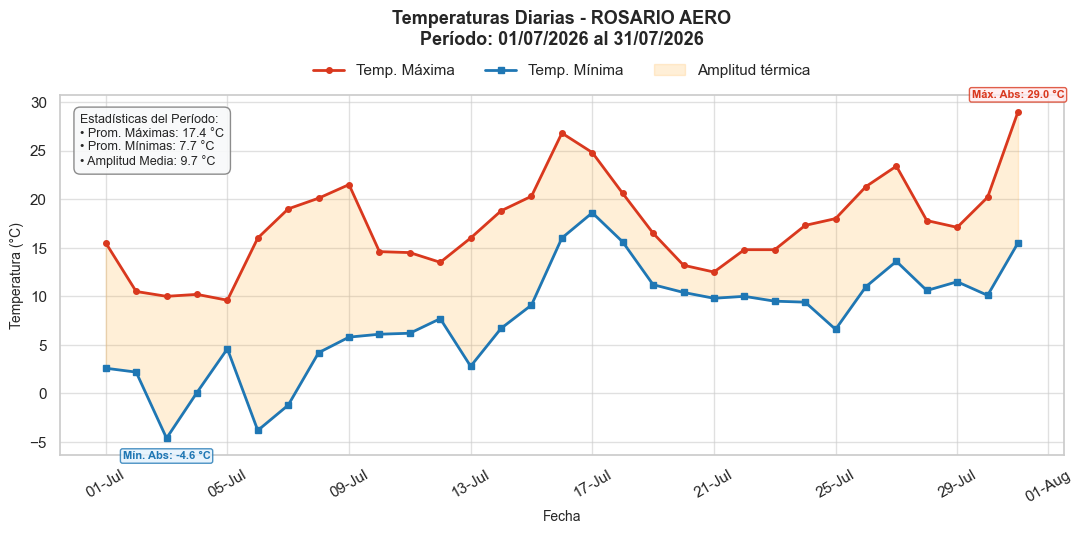

**Resumen estadístico del período:**
* **Temperatura Máxima Promedio:** 17,4 °C (con un valor máximo absoluto de 29,0 °C alcanzado el 31/07).
* **Temperatura Mínima Promedio:** 7,7 °C (con una mínima absoluta de -4,6 °C registrada el 03/07).

In [133]:
consultar_agente("Mostrame un gráfico de la temperatura máxima y mínima de Rosario durante julio de 2026")

Aquí tenés el gráfico con la evolución de las temperaturas máximas y mínimas registradas en la estación **BARILOCHE AERO** durante julio de 2026, incluyendo la amplitud térmica y los valores extremos del período.

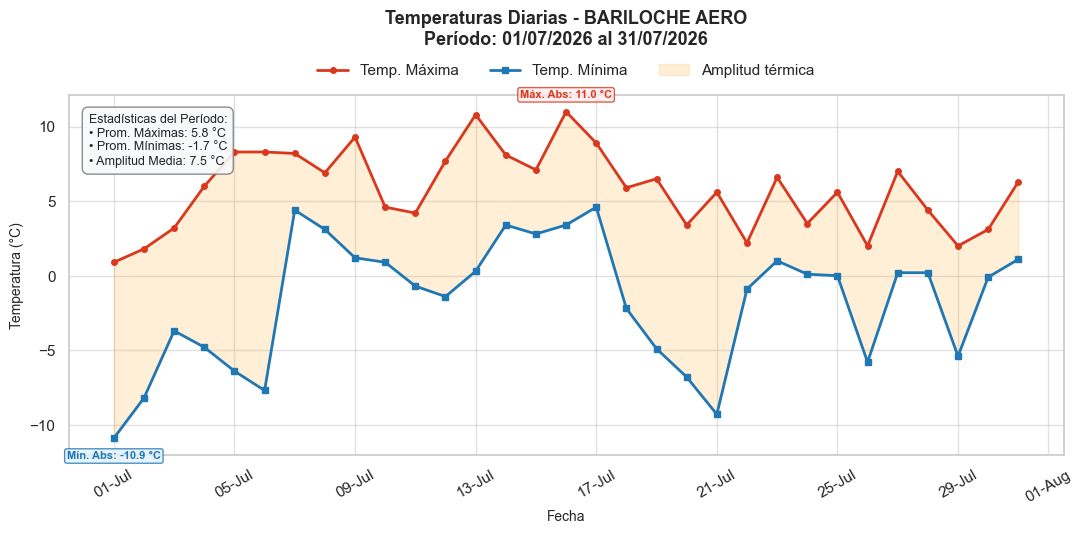

In [134]:
consultar_agente(
    "Graficame las temperaturas máximas y mínimas de Bariloche durante julio de 2026"
)

A continuación se presenta la comparación de las temperaturas máximas observadas en la estación **ROSARIO AERO** durante los meses de **junio y julio de 2026** en relación con las normales climatológicas (1991-2020):

### 1. Junio de 2026
* **Temperatura máxima promedio observada:** 16.8 °C
* **Normal climatológica (1991-2020):** 17.0 °C
* **Anomalía:** -0.2 °C (ligeramente por debajo de lo normal).

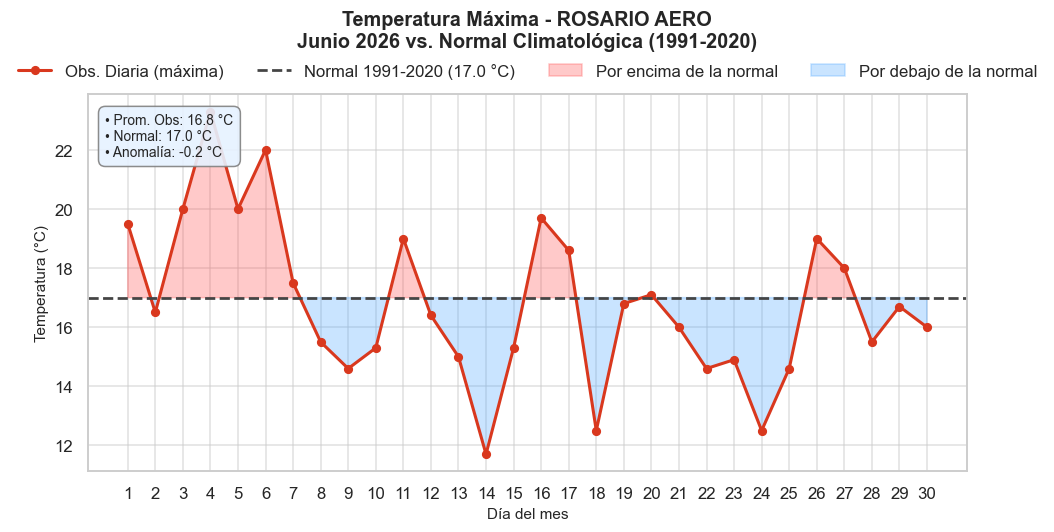

---

### 2. Julio de 2026
* **Temperatura máxima promedio observada:** 17.4 °C
* **Normal climatológica (1991-2020):** 16.5 °C
* **Anomalía:** +0.9 °C (por encima de lo normal).

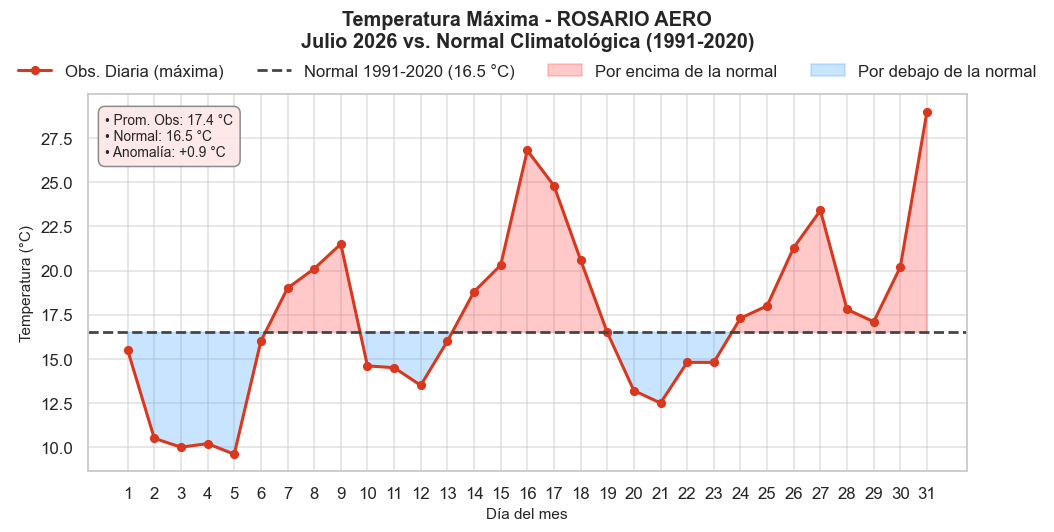

In [135]:
consultar_agente("Comparame la temperatura máxima de Rosario durante junio y julio de 2026 con la normal climatológica 1991-2020")

Durante el mes de julio de 2026, la temperatura máxima promedio registrada en ambas estaciones meteorológicas fue la siguiente:

* **CORDOBA AERO**: 18.0 °C promedio
* **ROSARIO AERO**: 17.4 °C promedio

Se observa que **CORDOBA AERO** tuvo una temperatura máxima promedio ligeramente superior (0.7 °C más alta) en comparación con **ROSARIO AERO**.

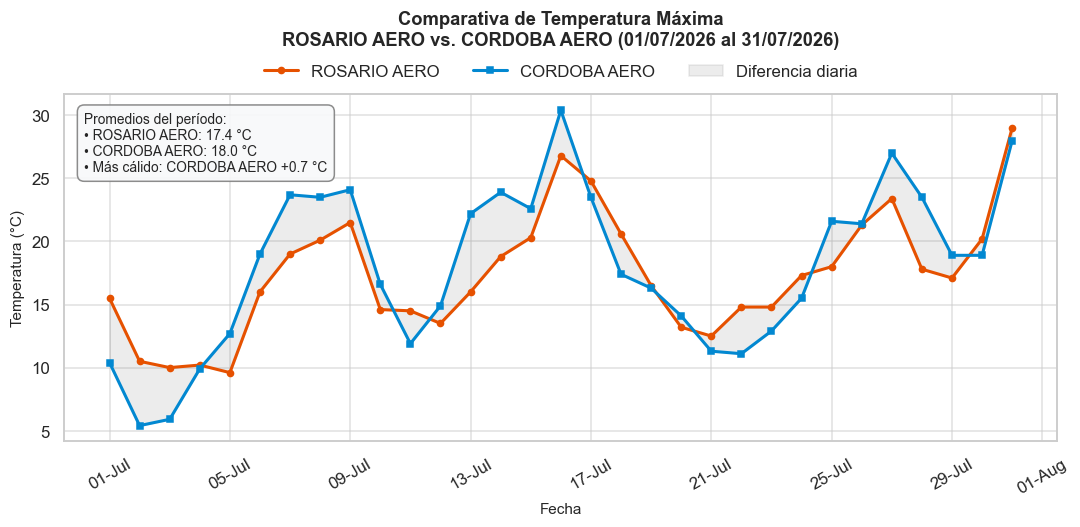

In [136]:
consultar_agente(
    "Comparame la temperatura máxima promedio de ROSARIO AERO y CORDOBA AERO durante julio de 2026"
)

In [ ]:
# Esta consulta es erronea, deberia responder que no hay datos
consultar_agente(
    "Graficame la temperatura de ROSARIO AERO durante enero de 1990"
)

No se encontraron registros de temperatura para la estación **ROSARIO AERO** durante el mes de enero de 1990 en la base de datos disponible. 

Si lo deseás, puedo consultar las temperaturas para otro período o de otra estación meteorológica cercana.

#### Listar estaciones

In [137]:
consultar_agente(
    "¿Qué estaciones meteorológicas hay en la provincia de Santa Fe?. ¿Y en Buenos Aires? ¿Y en CABA?"
)

A continuación, te presento el detalle de las estaciones meteorológicas del Servicio Meteorológico Nacional (SMN) en cada una de las regiones solicitadas:

### 🌾 Provincia de Santa Fe (7 estaciones)
* **Ceres Aero** (Código OACI: `SANW`, Altura: 88 m)
* **Rafaela Aero** (Código OACI: `SAFR`, Altura: 99 m)
* **Reconquista Aero** (Código OACI: `SATR`, Altura: 53 m)
* **Rosario Aero** (Código OACI: `SAAR`, Altura: 25 m)
* **Sauce Viejo Aero** (Código OACI: `SAAV`, Altura: 18 m)
* **Sunchales Aero** (Código OACI: `SAFS`, Altura: 92 m)
* **Venado Tuerto Aero** (Código OACI: `SAFV`, Altura: 112 m)

---

### 🌊 Provincia de Buenos Aires (principales estaciones)
*(La provincia cuenta con una amplia red; aquí se listan las primeras 20 estaciones registradas)*
* **Azul Aero** (`SAZA`, 147 m)
* **Bahía Blanca Aero** (`SAZB`, 83 m)
* **Benito Juárez Aero** (`SAZJ`, 207 m)
* **Bolívar Aero** (`SAZI`, 94 m)
* **Campo de Mayo Aero** (`SADO`, 26 m)
* **Coronel Suárez Aero** (`SAZC`, 233 m)
* **Dolores Aero** (`SAZD`, 9 m)
* **El Palomar Aero** (`SADP`, 12 m)
* **Ezeiza Aero** (`SAEZ`, 20 m)
* **Junín Aero** (`SAAJ`, 81 m)
* **La Plata Aero** (`SADL`, 23 m)
* **Las Flores** (`SAEL`, 36 m)
* **Mar del Plata Aero** (`SAZM`, 21 m)
* **Mariano Moreno Aero** (`SADJ`, 32 m)
* **Merlo Aero** (`SADR`, 24 m)
* **Morón Aero** (`SADM`, 24 m)
* **9 de Julio** (`SAZX`, 76 m)
* **Olavarría Aero** (`SAZF`, 166 m)
* **Pehuajó Aero** (`SAZP`, 87 m)
* **Pigüé Aero** (`SAZE`, 304 m)

---

### 🏙️ Ciudad Autónoma de Buenos Aires - CABA (2 estaciones)
* **Aeroparque Aero** (Código OACI: `SABE`, Altura: 6 m)
* **Buenos Aires Observatorio** (Código OACI: `SABA`, Altura: 25 m)

In [22]:
consultar_agente(
    "Dame la ubicación, altura y códigos de la estación Rosario, y las de Jujuy (provincia)"
)

Aquí tenés la información detallada de ubicación, altura y códigos de las estaciones solicitadas:

### 📍 Estación Rosario (Provincia de Santa Fe)
* **Estación:** ROSARIO AERO
* **Provincia:** Santa Fe
* **Ubicación:** Latitud -32.9°, Longitud -60.77°
* **Altura:** 25 metros
* **Códigos:** 
  * N° SMN: 87480
  * OACI: SAAR

---

### 📍 Estaciones de la Provincia de Jujuy

1. **JUJUY AERO**
   * **Ubicación:** Latitud -24.38°, Longitud -65.08°
   * **Altura:** 909 metros
   * **Códigos:** 
     * N° SMN: 87046
     * OACI: SASJ

2. **JUJUY U N**
   * **Ubicación:** Latitud -24.17°, Longitud -65.32°
   * **Altura:** 1302 metros
   * **Códigos:** 
     * N° SMN: 87043
     * OACI: *No disponible (nan)*

3. **LA QUIACA OBSERVATORIO**
   * **Ubicación:** Latitud -22.10°, Longitud -65.60°
   * **Altura:** 3459 metros
   * **Códigos:** 
     * N° SMN: 87007
     * OACI: SASQ

#### Consultas a la base vectorial

In [150]:
consultar_agente("Qué documentos tenés disponibles para consultar?")

Tengo disponibles los siguientes documentos e informes meteorológicos en la base de datos:

* **Informes mensuales (2026):**
  * `Clim-Enero 2026.pdf`
  * `Clim-Febrero 2026.pdf`
  * `Clim-Marzo 2026.pdf`
  * `Clim-Abril 2026.pdf`
  * `Clim-Mayo 2026.pdf`
  * `Clim-Junio 2026.pdf`
  * `Clim-Julio 2026.pdf`

* **Informes estacionales y especiales (2026):**
  * `Clin-Verano 2025-26.pdf` (Informe del Verano 2025-2026)
  * `Clim-Otoño 2026.pdf` (Informe del Otoño 2026)
  * `OladeFrio_18al31_julio2026.pdf` (Informe sobre la ola de frío del 18 al 31 de julio de 2026)
  * `elnino26_09.pdf` (Informe sobre el fenómeno de El Niño - septiembre 2026)
  * `pronostico_climatico_trimestral_092026.pdf` (Pronóstico climático trimestral - septiembre 2026)

Podés consultarme sobre el contenido de cualquiera de estos documentos, resúmenes climáticos, eventos destacados o análisis detallados de los períodos mencionados.

In [49]:
consultar_agente("Según los informes del SMN, ¿cómo fueron las precipitaciones durante mayo de 2026?. Además, cómo se compararon con otoño 2026?")

Según los informes del Servicio Meteorológico Nacional (SMN) para el año 2026, las características de las precipitaciones en **mayo de 2026** y su relación con el contexto general del **otoño de 2026** se detallan a continuación:

### **Precipitaciones en Mayo de 2026**
* **Escasez generalizada:** Gran parte del país (incluyendo el Noroeste Argentino - NOA, Cuyo y el centro/zona central de la Patagonia) registró acumulados inferiores a los 20 mm. En varias localidades, como La Quiaca o Ceres, **no se registraron precipitaciones** durante todo el mes.
* **Frecuencia de días con lluvia:** Predominaron las anomalías negativas en la cantidad de días con precipitaciones en gran parte del territorio nacional (con menores registros en zonas como Dolores, Concordia y Ezeiza).
* **Eventos extremos puntuales:** A pesar de la sequía predominante, se destacaron algunos eventos aislados de lluvias y tormentas fuertes en Chaco, el este de Buenos Aires y el norte de Entre Ríos. 
* **Excepciones húmedas:** Los mayores acumulados diarios y desvíos positivos se registraron de manera muy localizada, destacándose la zona cordillerana de Neuquén (con registros superiores a los 300-500 mm en puntos específicos como Cerro Mirador) y algunos sectores de la provincia de Buenos Aires (como Tres Arroyos y Mar del Plata).

---

### **Comparación con el Otoño de 2026 (Marzo, Abril y Mayo)**
* **Comportamiento estacional vs. mensual:** Mientras que mayo se caracterizó por una marcada escasez de lluvias y anomalías negativas generalizadas, el **otoño de 2026 en su conjunto** presentó acumulados muy significativos.
* **Volúmenes acumulados estacionales:** Durante toda la estación otoñal, las precipitaciones superaron los **400 mm** en amplias regiones del norte y centro del país (como gran parte de Formosa y Chaco, norte de Corrientes y Santa Fe, sudeste de Santiago del Estero y el centro de Buenos Aires), evidenciando que los meses previos (marzo y/o abril) compensaron con creces la sequía experimentada en el tramo final del otoño (mayo).

In [25]:
consultar_agente(
    "¿Qué informa el SMN sobre El Niño durante 2026?"
)

De acuerdo con los informes del Servicio Meteorológico Nacional (SMN), la situación y las perspectivas sobre **El Niño** durante **2026** indican lo siguiente:

* **Fase cálida consolidada:** Los análisis y modelos muestran una clara consistencia con el desarrollo y mantenimiento de una fase cálida (El Niño).
* **Probabilidad para el trimestre SON (septiembre-octubre-noviembre) 2026:** Existe un **100% de probabilidad** de que la fase de El Niño se mantenga durante dicho trimestre.
* **Temperaturas Superficiales del Mar (TSM):** 
  * Los pronósticos computacionales en la región Niño 3.4 prevén TSM superiores a sus valores normales, con un valor promedio entre los modelos cercano a **+3 °C**.
  * Hacia finales de agosto de 2026, las anomalías registradas en las distintas regiones del fenómeno fueron:
    * **Niño 1+2:** +3.5 °C
    * **Niño 3:** +2.6 °C
    * **Niño 3.4:** +1.8 °C
    * **Niño 4:** +0.1 °C (valores cercanos a los normales)
* **Intensidad del evento:** Respecto a la intensidad que alcanzará el fenómeno, los modelos probabilísticos indican que las mayores chances apuntan a que sea un evento **muy fuerte**.

In [26]:
consultar_agente(
    "¿Qué pronóstico de temperatura y precipitación presenta el SMN para septiembre, octubre y noviembre de 2026 en Argentina?"
)

Según el **Pronóstico Climático Trimestral** elaborado por el Servicio Meteorológico Nacional (SMN) el **28 de agosto de 2026**, para el trimestre **septiembre, octubre y noviembre de 2026** se destacan los siguientes aspectos generales sobre la temperatura y la precipitación en la Argentina:

### 🌡️ **Temperatura Media**
* El pronóstico probabilístico por consenso evalúa la ocurrencia de la temperatura media trimestral en tres categorías: **superior a la normal, normal o inferior a la normal**.
* El informe señala que las previsiones se deben considerar sobre el valor medio del trimestre (período de referencia climatológica 1991-2020), recordando que el tercil central abarca valores de aproximadamente 0,5 °C por debajo o por encima del valor medio.
* **Nota importante:** Estas perspectivas climáticas reflejan condiciones medias trimestrales y no descartan la ocurrencia de singularidades de escala subestacional, tales como olas de frío o de calor, ingresos de sistemas frontales o bloqueos atmosféricos.

### 🌧️ **Precipitación**
* El pronóstico de precipitaciones delimita las probabilidades para las categorías **superior, normal e inferior a la normal** en las distintas regiones del país.
* Aquéllas áreas presentadas sin una categoría predominante (áreas en blanco en los mapas oficiales) indican que no existe una señal clara en los modelos, por lo que se sugiere considerar la información estadística histórica del trimestre.
* Cabe destacar que, de acuerdo con los modelos dinámicos y estadísticos analizados para este mismo trimestre, se prevé la persistencia de condiciones consistentes con la fase cálida (**El Niño**).

> **Recomendación:** Se sugiere mantenerse actualizado de manera permanente con los pronósticos de escala diaria y semanal emitidos por el SMN.

In [33]:
consultar_agente(
    "Según el pronóstico trimestral del SMN, ¿qué regiones de Argentina tienen mayor probabilidad de registrar temperaturas superiores a lo normal entre septiembre y noviembre de 2026?"
)

Según el **Pronóstico Climático Trimestral (septiembre-octubre-noviembre 2026)** del Servicio Meteorológico Nacional, las regiones de Argentina con mayor probabilidad de registrar temperaturas medias **superiores a lo normal** (**SN**) o con tendencia **normal a superior a lo normal** (**N-SN**) se distribuyen de la siguiente manera:

*   **Región del Litoral y Noreste (NEA):** Presenta condiciones marcadas hacia categorías **superiores a lo normal** (**SN**), alineadas con la persistencia de la fase cálida (El Niño) prevista para el trimestre.
*   **Zona Central y Buenos Aires:** Muestra mayor probabilidad de registrar valores **normales o superiores a lo normal** (**N-SN**).
*   **Región de Cuyo y Noroeste Argentino (NOA):** Muestra áreas con tendencia hacia registros **superiores a lo normal** (**SN**) y otras de transición **normal a superior a lo normal** (**N-SN**).
*   **Patagonia:** Presenta un comportamiento más variable según los sectores, alternando zonas con mayor probabilidad de valores normales o con menor incidencia cálida directa respecto al norte del país.

*Nota:* Esta previsión se refiere a las condiciones medias del trimestre y no contempla eventos de escala subestacional como olas de calor o irrupciones de aire frío.

In [46]:
consultar_agente(
    "¿Cuáles fueron las principales características de la ola de frío analizada por el SMN durante 2026 y qué regiones fueron afectadas?"
)

De acuerdo con el **Informe Especial N°2 por Ola de Frío / Bajas Temperaturas (Temporada 2026)** elaborado por el SMN, las principales características y regiones afectadas del evento ocurrido entre el **18 y el 31 de julio de 2026** fueron las siguientes:

### **Regiones Afectadas**
* **Patagonia (principalmente Santa Cruz y Chubut):** La provincia de **Santa Cruz** fue la más castigada tanto en intensidad como en duración del fenómeno.

### **Principales Características**
* **Ingreso y bloqueo de aire polar:** Una masa de aire frío polar ingresó por el extremo sur de la Patagonia el 17 de julio y avanzó hasta Chubut. Sin embargo, quedó estancada en la zona debido a una **fuerte circulación zonal entre los 30°S y 40°S**, lo que bloqueó su avance hacia latitudes más bajas (impidiendo que las condiciones de frío extremo se propagaran hacia el norte del país, como suele suceder habitualmente).
* **Intensidad y persistencia:** El evento se definió por varios días consecutivos con temperaturas máximas y mínimas inferiores a los umbrales establecidos para considerar frío extremo.
* **Fenómenos asociados:** La persistencia de las bajas temperaturas estuvo acompañada por **nevadas** y el **congelamiento de los suelos**. Asimismo, hacia el **29 de julio** se registró un refuerzo de aire frío en la región.
* **Nevadas extraordinarias asociadas:** En paralelo, se registraron nevadas extraordinarias en la **región cordillerana central y norte**, con acumulados eﬁcaces superiores a los **3 metros de altura** en provincias como **Catamarca, San Juan y Mendoza**.

#### Mapas de provincias / país

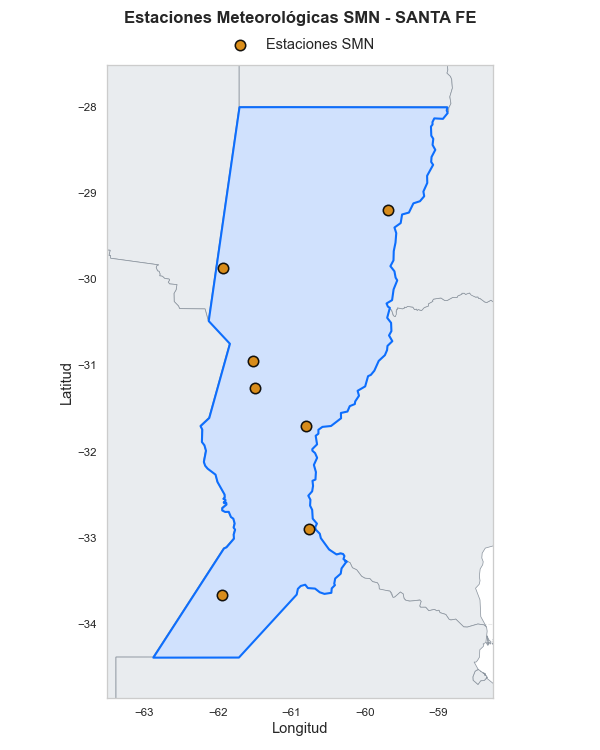

In [139]:
consultar_agente(
  "Quisiera ver un mapa de las estaciones meteorologicas en Santa Fe"
)

Aquí tenés los mapas con la distribución de las estaciones meteorológicas del SMN para las regiones solicitadas y a nivel nacional:

### Provincia de Buenos Aires

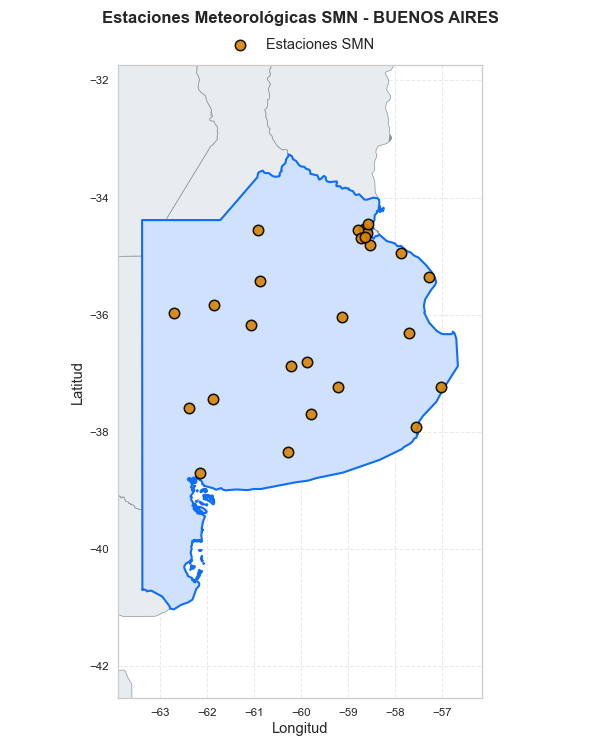

### Provincia de Tierra del Fuego

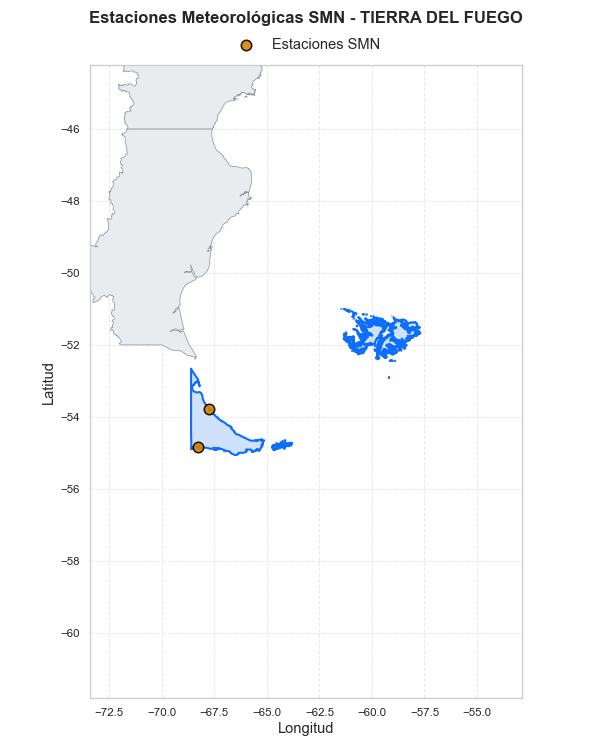

### Antártida

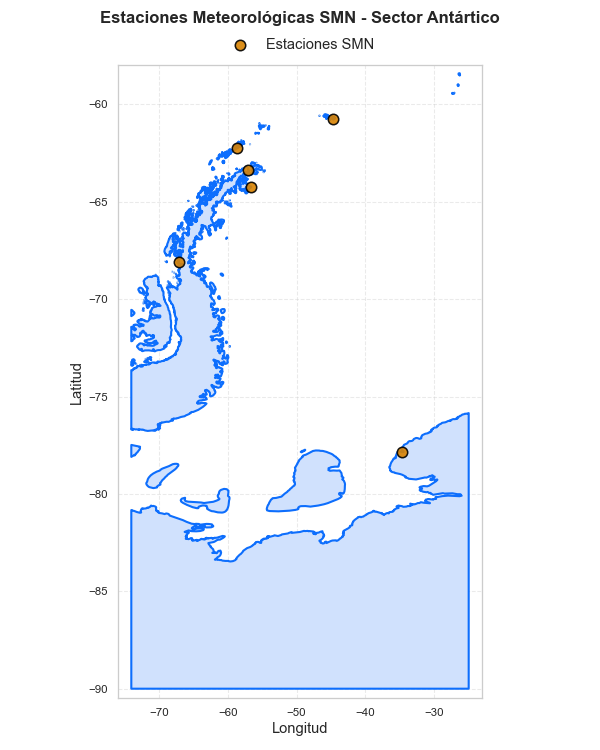

### Todo el País

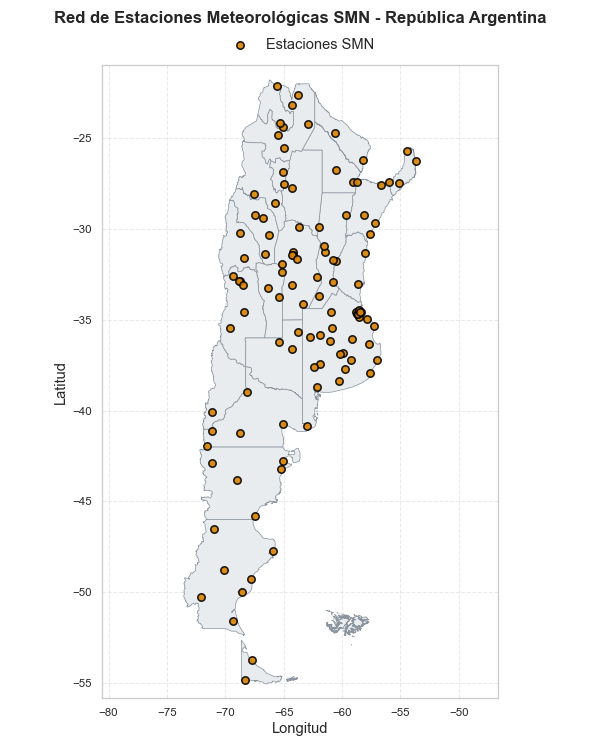

In [140]:
consultar_agente(
  "Quisiera ver un mapa de las estaciones meteorologicas en buenos aires, antartida, tierra del fuego, y todo el pais"
)

#### Climogramas

Aquí tenés los climogramas correspondientes a las estaciones meteorológicas solicitadas, que muestran la marcha anual de las temperaturas medias y las precipitaciones mensuales:

### Rosario

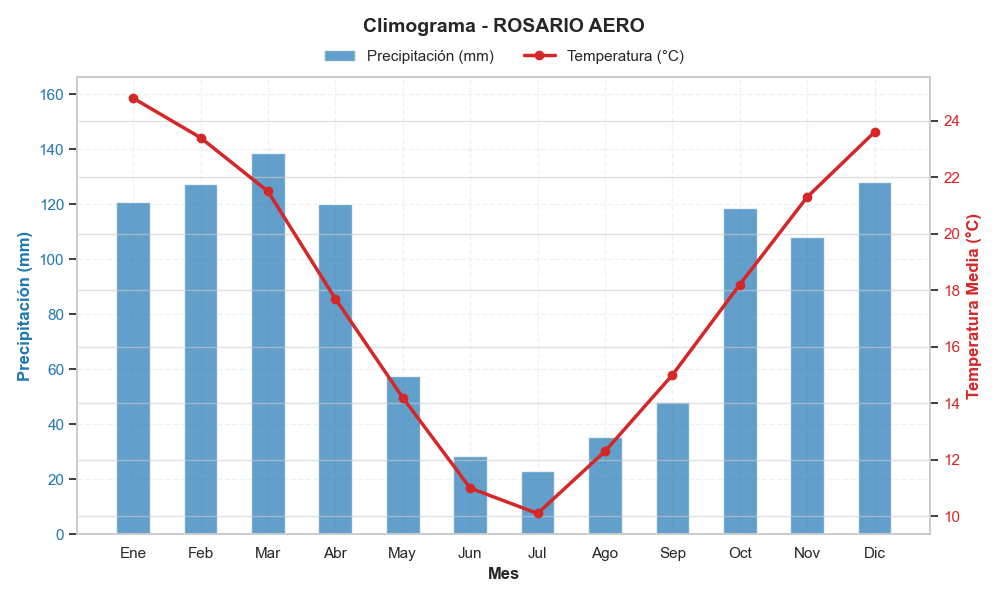

---

### La Quiaca

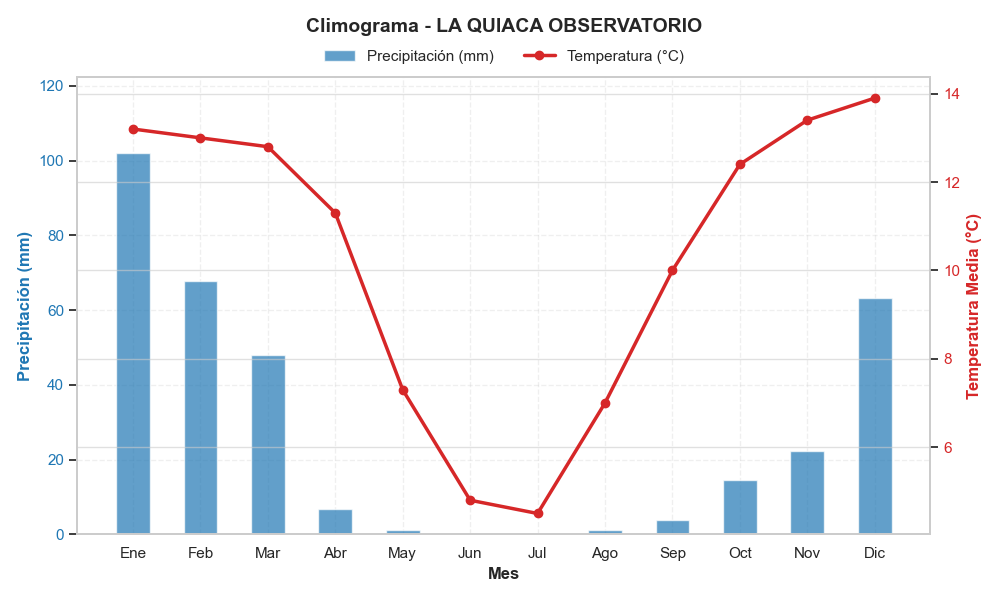

---

### Ushuaia

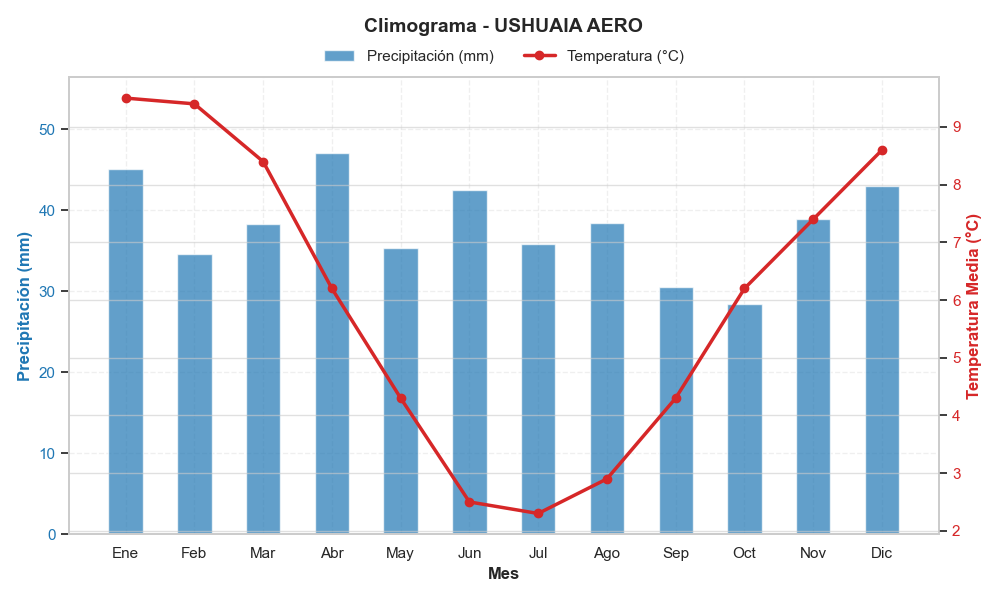

In [141]:
consultar_agente("Quisiera ver los climogramas de Rosario, La Quiaca y Ushuaia")

#### Consultas complejas con múltiples herramientas 

### 1. Evolución de las temperaturas en Rosario durante Julio de 2026
Durante el mes de julio de 2026, la estación **Rosario Aero** registró los siguientes valores y comportamiento térmico:
* **Temperatura Máxima Promedio:** 17.4 °C (con un valor máximo absoluto de 29.0 °C alcanzado el 31/07).
* **Temperatura Mínima Promedio:** 7.7 °C (con una mínima absoluta de -4.6 °C registrada el 03/07).

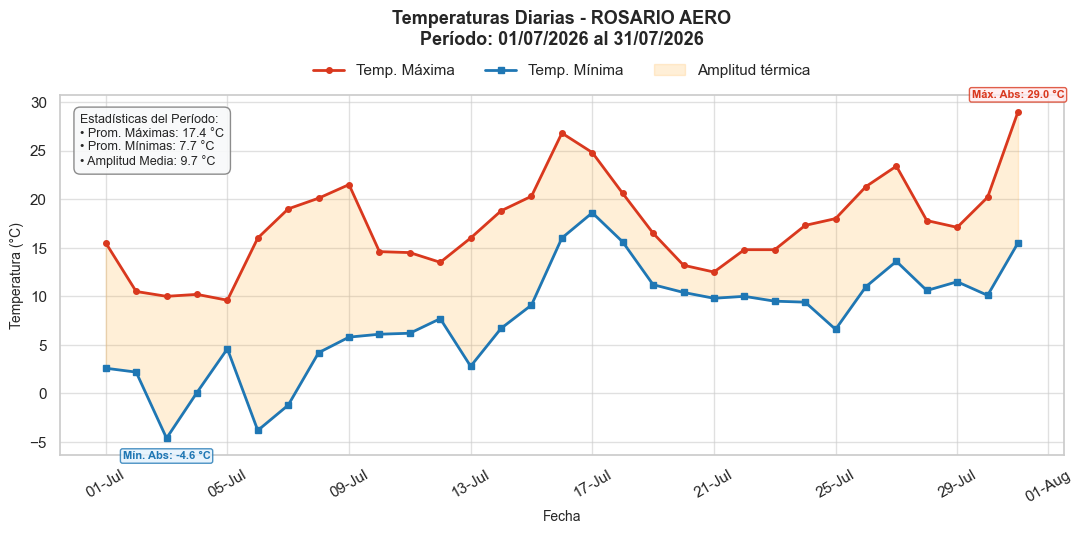

---

### 2. Comparación con las temperaturas normales
Al comparar la temperatura máxima observada en **Rosario Aero** con la normal climatológica del período 1991-2020 para el mes de julio (16.5 °C), se observa una **anomalía positiva de +0.9 °C**, ubicándose ligeramente por encima de los valores normales esperados para el mes.

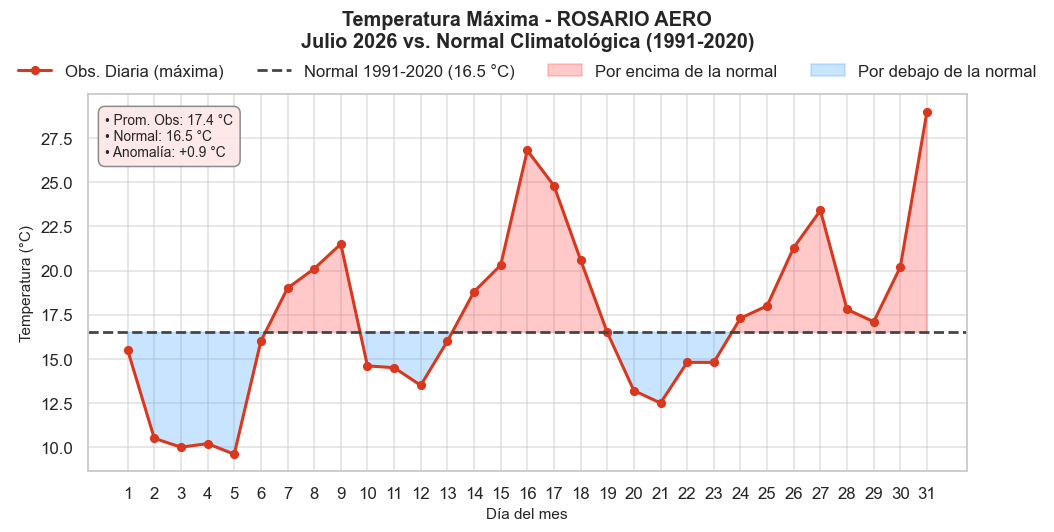

---

### 3. Estaciones meteorológicas en la Provincia de Santa Fe y Mapa de Ubicación
En la provincia de Santa Fe hay un total de **7 estaciones meteorológicas** operadas por el SMN:
* **Ceres Aero** (Código SMN: 87257)
* **Rafaela Aero** (Código SMN: 87360)
* **Reconquista Aero** (Código SMN: 87270)
* **Rosario Aero** (Código SMN: 87480)
* **Sauce Viejo Aero** (Código SMN: 87371)
* **Sunchales Aero** (Código SMN: 87356)
* **Venado Tuerto Aero** (Código SMN: 87468)

A continuación se muestra el mapa con la ubicación geográfica de dichas estaciones en la provincia:

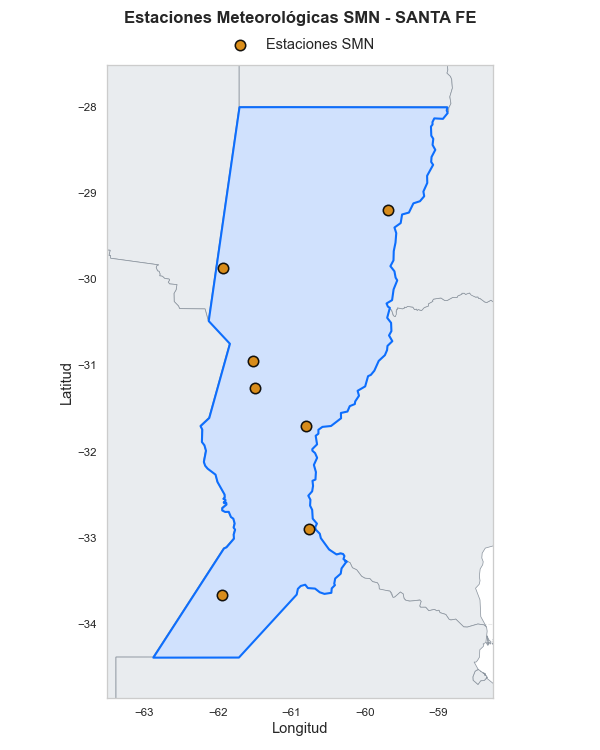

---

### 4. Descripción de la ola de frío de 2026
De acuerdo con el *Informe Especial N° 2 por Ola de Frío / Bajas Temperaturas (Temporada 2026)* del Servicio Meteorológico Nacional, el evento principal se desarrolló **entre el 18 y el 31 de julio de 2026**:

* **Ingreso y bloqueos:** Una masa de aire frío polar ingresó por el extremo sur de la Patagonia el 17 de julio, avanzando hasta Chubut y quedando estancada debido a una fuerte circulación zonal entre los 30°S y 40°S que bloqueó su avance hacia latitudes más norteñas.
* **Provincias más afectadas:** La provincia de **Santa Cruz** y **Chubut** sufrieron los mayores impactos en cuanto a intensidad y duración de las bajas temperaturas, acompañadas por congelamiento de suelos.
* **Refuerzo frío y nevadas extraordinarias:** Un nuevo refuerzo de aire frío ingresó a partir del 29 de julio. El fenómeno estuvo asociado a nevadas extraordinarias en la región cordillerana central y norte —con acumulados superiores a los **3 metros de altura** en provincias como **Catamarca, San Juan y Mendoza**—.

In [142]:
consultar_agente(
  """Hola, necesito que respondas a lo siguiente:
  - Como evolucionaron las temperaturas en Rosario durante Julio de 2026?
  - Y como se compara con las temperaturas normales?
  - Cuantas estaciones meteorologicas hay en Santa Fe? Tambien quisiera ver un mapa para saber en donde se encuentran.
  - Por ultimo, quisiera que describas la ola de frio que ocurrio en 2026.
  """
)

#### Consultas interactivas

🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada
Escribí 'salir', 'exit' o 'chau' para terminar la conversación.



**👤 Usuario:** De que estaba hablando?


🤖 Agente:


Parece que esta es nuestra primera interacción o que la conversación anterior se ha reiniciado, ya que no tengo registro de lo que estabas comentando previamente. 

¿De qué te gustaría que hablemos o en qué te puedo ayudar? 

Para que sepas de qué disponemos, puedo ayudarte con:
* **Consultas de estaciones meteorológicas** (buscar estaciones por provincia o nombre, u obtener su ubicación y altura).
* **Análisis y gráficos de temperatura** (generar gráficos de temperaturas máximas y mínimas para un rango de fechas).
* **Comparaciones térmicas** (comparar temperaturas entre dos estaciones o contra las normales climatológicas 1991-2020).
* **Mapas** (generar mapas con la ubicación de las estaciones a nivel nacional o filtradas por provincia).
* **Informes climáticos** (buscar explicaciones conceptuales y detalles de informes meteorológicos almacenados).

¡Contame qué tema tenías en mente y lo retomamos!

------------------------------------------------------------


**👤 Usuario:** Mostrame un mapa de las estaciones de buenos aires, tambien una lista


🤖 Agente:


Aquí tenés el mapa con la ubicación de las estaciones meteorológicas en la provincia de Buenos Aires:

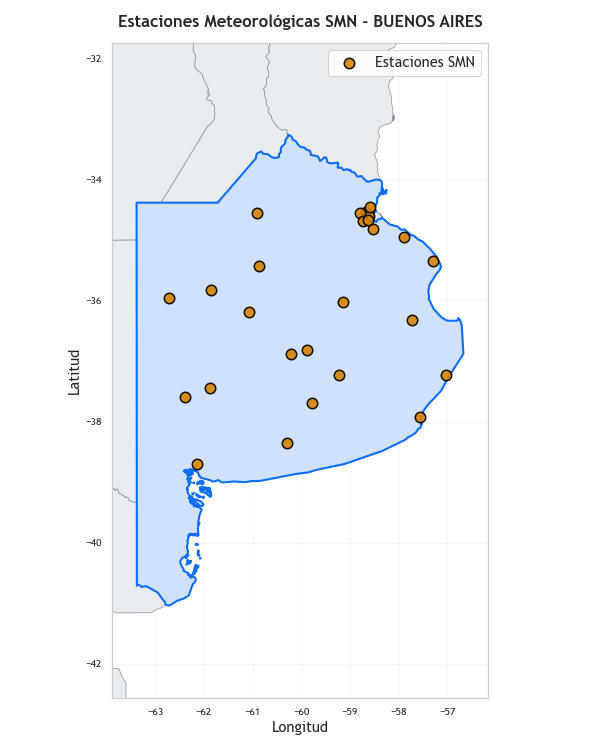

Y a continuación, el listado de las estaciones disponibles en la provincia (mostrando las primeras 20):

* **AZUL AERO** — Lat: -36.82° | Lon: -59.88° | Altura: 147 m | OACI: SAZA
* **BAHIA BLANCA AERO** — Lat: -38.70° | Lon: -62.15° | Altura: 83 m | OACI: SAZB
* **BENITO JUAREZ AERO** — Lat: -37.70° | Lon: -59.78° | Altura: 207 m | OACI: SAZJ
* **BOLIVAR AERO** — Lat: -36.18° | Lon: -61.07° | Altura: 94 m | OACI: SAZI
* **CAMPO DE MAYO AERO** — Lat: -34.53° | Lon: -58.67° | Altura: 26 m | OACI: SADO
* **CORONEL SUAREZ AERO** — Lat: -37.45° | Lon: -61.88° | Altura: 233 m | OACI: SAZC
* **DOLORES AERO** — Lat: -36.32° | Lon: -57.72° | Altura: 9 m | OACI: SAZD
* **EL PALOMAR AERO** — Lat: -34.60° | Lon: -58.60° | Altura: 12 m | OACI: SADP
* **EZEIZA AERO** — Lat: -34.82° | Lon: -58.53° | Altura: 20 m | OACI: SAEZ
* **JUNIN AERO** — Lat: -34.55° | Lon: -60.92° | Altura: 81 m | OACI: SAAJ
* **LA PLATA AERO** — Lat: -34.95° | Lon: -57.88° | Altura: 23 m | OACI: SADL
* **LAS FLORES** — Lat: -36.03° | Lon: -59.13° | Altura: 36 m | OACI: SAEL
* **MAR DEL PLATA AERO** — Lat: -37.92° | Lon: -57.57° | Altura: 21 m | OACI: SAZM
* **MARIANO MORENO AERO** — Lat: -34.55° | Lon: -58.78° | Altura: 32 m | OACI: SADJ
* **MERLO AERO** — Lat: -34.68° | Lon: -58.73° | Altura: 24 m | OACI: SADR
* **MORON AERO** — Lat: -34.67° | Lon: -58.63° | Altura: 24 m | OACI: SADM
* **NUEVE DE JULIO** — Lat: -35.43° | Lon: -60.87° | Altura: 76 m | OACI: SAZX
* **OLAVARRIA AERO** — Lat: -36.88° | Lon: -60.22° | Altura: 166 m | OACI: SAZF
* **PEHUAJO AERO** — Lat: -35.83° | Lon: -61.85° | Altura: 87 m | OACI: SAZP
* **PIGUE AERO** — Lat: -37.60° | Lon: -62.38° | Altura: 304 m | OACI: SAZE

------------------------------------------------------------


**👤 Usuario:** Podes hacer lo mismo para la antartida?


🤖 Agente:


Aquí tenés el mapa con la ubicación de las estaciones meteorológicas en el sector antártico:

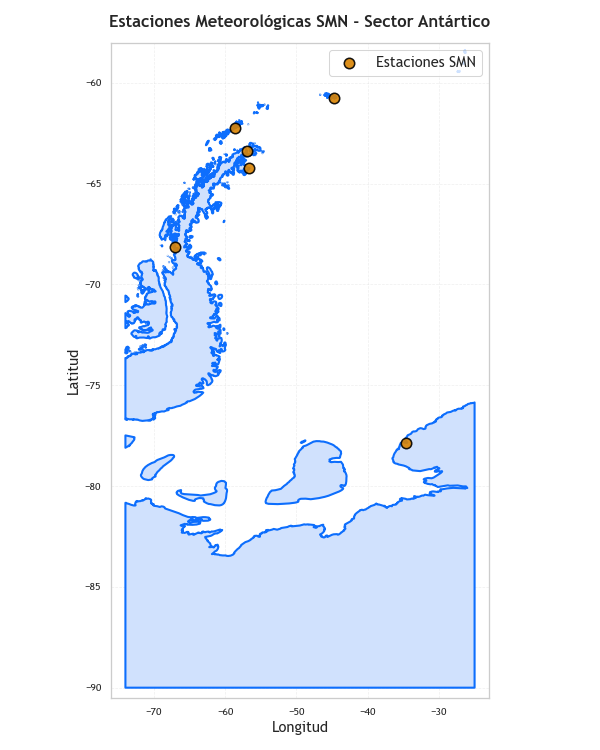

Y a continuación, el listado completo de las estaciones disponibles en la Antártida:

* **BASE BELGRANO II** — Lat: -77.87° | Lon: -34.62° | Altura: 256 m | OACI: SAYB
* **BASE CARLINI (EX JUBANY)** — Lat: -62.23° | Lon: -58.65° | Altura: 11 m | OACI: SAYJ
* **BASE ESPERANZA** — Lat: -63.38° | Lon: -56.98° | Altura: 24 m | OACI: SAYE
* **BASE MARAMBIO** — Lat: -64.23° | Lon: -56.62° | Altura: 198 m | OACI: SAWB
* **BASE ORCADAS** — Lat: -60.73° | Lon: -44.73° | Altura: 12 m | OACI: SAYO
* **BASE SAN MARTIN** — Lat: -68.12° | Lon: -67.10° | Altura: 7 m | OACI: SAYS

------------------------------------------------------------

👋 Sesión finalizada. ¡Hasta luego!



In [71]:
iniciar_chat_interactivo()

In [25]:
iniciar_chat_interactivo()

🤖 Asistente Meteorológico SMN - Sesión Interactiva Iniciada
Escribí 'salir', 'exit' o 'chau' para terminar la conversación.



**👤 Usuario:** Dame una receta de panqueques, aparte de eso quiero una lista de estaciones en CABA


🤖 Agente:


### Receta clásica de panqueques (para dulce o salado)

**Ingredientes:**
* 1 taza de harina leudante (o harina común con 1 cucharadita de polvo para hornear)
* 1 taza de leche
* 1 huevo
* 1 pizca de sal (o 1 cucharadita de azúcar si los preferís dulces)
* Manteca o aceite para lubricar la sartén

**Preparación:**
1. En un bol, colocá el huevo y batilo ligeramente.
2. Agregá la mitad de la leche y la harina tamizada de a poco, batiendo constantemente para evitar que se formen grumos.
3. Incorporá el resto de la leche y la pizca de sal (o azúcar). Mezclá bien hasta obtener una preparación líquida y homogénea.
4. Calentá una sartén (idealmente antiadherente) a fuego medio y pasale un poquito de manteca o aceite.
5. Verté un cucharón chico de mezcla en el centro de la sartén y movela rápidamente para cubrir toda la base de forma pareja.
6. Cociná durante 1 o 2 minutos hasta que los bordes se doren y se desprendan solos. Dalo vuelta y cociná unos segundos más del otro lado.
7. Repetite el proceso hasta terminar la mezcla. ¡Listo para rellenar con dulce de leche, jamón y queso, o lo que prefieras!

---

### Estaciones meteorológicas en CABA (Ciudad Autónoma de Buenos Aires)

Según los registros del Servicio Meteorológico Nacional (SMN), en la Ciudad Autónoma de Buenos Aires se encuentran las siguientes estaciones:

1. **AEROPARQUE AERO**
   * **Provincia:** Capital Federal
   * **Latitud:** -34.55 | **Longitud:** -58.42
   * **Altura:** 6 m
   * **Código SMN:** 87582.0 | **OACI:** SABE

2. **BUENOS AIRES OBSERVATORIO**
   * **Provincia:** Capital Federal
   * **Latitud:** -34.58 | **Longitud:** -58.48
   * **Altura:** 25 m
   * **Código SMN:** 87585.0 | **OACI:** SABA

------------------------------------------------------------


...

------------------------------------------------------------


**👤 Usuario:** Entonces los panqueques los puedo rellenar con dulce de leche?


🤖 Agente:


¡Jaja! En el terreno culinario gastronómico seguro que sí, ¡con dulce de leche quedan riquísimos! Pero por el lado de la atmósfera y la meteorología, te cuento que por acá no tenemos ninguna "masa de aire caliente" ni "frente frío" que se le parezca a un panqueque, ¡aunque a veces las nubes altas y delgadas (como los cirros) parezcan sábanas finitas!

Si volvemos a la atmósfera real, ¿te gustaría que analicemos alguna estación meteorológica, comparemos temperaturas o veamos algún informe del clima? ¡Para eso sí que estoy listo!

------------------------------------------------------------

👋 Sesión finalizada. ¡Hasta luego!

